# Previsão da demanda horária de corridas da Uber por zona de Nova York com Spark ML

**Disciplina:** Processamento de Dados Massivos — IESB
**Professor:** Alexandre Roriz
**Aluno:** Ilton Ferreira Mendes Neto
**Tipo de problema (sorteio):** Regressão

---

**Resumo.** A partir de 14,27 milhões de registros de embarques da Uber em Nova York (janeiro a junho de 2015), o notebook constrói, com PySpark e Spark ML, um modelo que prevê **quantas corridas cada zona da cidade terá na próxima hora**. Todo o pipeline roda no Spark: ingestão com schema manual, limpeza, agregação para a grade zona × hora, criação de atributos temporais com funções de janela, `Pipeline` de transformação, ajuste de hiperparâmetros com validação temporal, comparação com referências ingênuas, interpretação e persistência do modelo com `save()`.

**Sumário**
1. Contextualização
2. Ingestão
3. Exploração e limpeza
4. Engenharia de atributos e `Pipeline`
5. Modelagem
6. Avaliação e interpretação
7. Persistência
8. Conclusão

## 1. Contextualização

### 1.1 A base de dados

| Item | Descrição |
|---|---|
| **Nome** | Uber TLC FOIL Response — *uber-raw-data-janjune-15* |
| **Origem** | Registros de viagens que a Uber é obrigada a reportar à *NYC Taxi & Limousine Commission* (TLC). O site FiveThirtyEight obteve os dados junto à TLC por meio de um pedido de acesso à informação (FOIL, *Freedom of Information Law*) e os publicou abertamente. |
| **Link de acesso** | https://github.com/fivethirtyeight/uber-tlc-foil-response (arquivo `uber-trip-data/uber-raw-data-janjune-15.csv.zip`) |
| **Tabela auxiliar** | `uber-trip-data/taxi-zone-lookup.csv` — nome e distrito (*borough*) de cada uma das 265 zonas de táxi da TLC (mesmo repositório) |
| **Período** | 01/01/2015 a 30/06/2015 |
| **Registros** | 14.270.479 embarques (um por linha) |
| **Colunas** | 4: `Dispatching_base_num` (base da Uber que despachou a corrida), `Pickup_date` (data e hora do embarque), `Affiliated_base_num` (base à qual o veículo é afiliado) e `locationID` (zona TLC de embarque, 1 a 265) |
| **Tamanho** | 70,7 MB compactado; 551,7 MB descompactado (CSV) |

**É uma amostra?** Não aplicamos amostragem: o notebook usa **100% do arquivo** publicado, que é a resposta integral da TLC para as viagens da Uber no 1º semestre de 2015. Esse arquivo é, porém, um **recorte** de um universo bem maior — os registros de todas as empresas de transporte por aplicativo e táxis que a TLC acumula desde 2009 (bilhões de viagens). O recorte é de natureza temporal (um semestre) e de empresa (só Uber), não aleatório. Na etapa de modelagem também restringimos a análise às zonas com demanda operacionalmente relevante (média ≥ 10 corridas/dia no período de treino), critério detalhado na seção 4.

### 1.2 Pergunta de negócio

> **Quantas corridas a Uber terá em cada zona de Nova York na próxima hora?**

Prever a demanda por zona e por hora é o insumo central de três decisões de uma plataforma de mobilidade:

* **Reposicionamento de motoristas** — enviar carros vazios para onde a demanda vai surgir reduz o tempo de espera do passageiro e o tempo ocioso do motorista;
* **Preço dinâmico** — antecipar desequilíbrios entre oferta e demanda permite ajustar incentivos antes que a fila se forme;
* **Planejamento de capacidade** — dimensionar a frota necessária por região e horário.

O problema é formulado como **regressão**: a variável-alvo é o número de corridas (`corridas`) em uma zona durante uma hora, e a previsão é feita **uma hora à frente**, usando apenas informação disponível até o fim da hora anterior.

### 1.3 Por que é um problema de dados massivos

Não basta que a base seja grande; o que importa é que o **cenário** exija processamento distribuído. Pelos conceitos da disciplina (os "Vs" de *Big Data* e o modelo de processamento particionado do Spark):

1. **Volume.** Uma única empresa, em uma única cidade, gerou 14,3 milhões de registros em seis meses. Hoje o volume é muito maior: em agosto de 2024 Uber e Lyft completaram **mais de 18 milhões de viagens em um único mês** em Nova York, segundo depoimento da própria TLC ao Conselho Municipal ([TLC, 27/09/2024](https://www.nyc.gov/assets/tlc/downloads/pdf/testimony_9_27_24.pdf)) — cerca de 220 milhões por ano, só nesse segmento. Um sistema de previsão em produção precisa reprocessar esse histórico continuamente; a memória de uma única máquina (o modelo do pandas) deixa de ser suficiente.
2. **Velocidade.** A previsão precisa ser refeita a cada hora (ou a cada poucos minutos) para todas as zonas, à medida que novas corridas chegam. É o caso de uso típico de processamento incremental/*streaming* (Spark Structured Streaming), que reaproveita o mesmo código de transformação deste notebook.
3. **Explosão combinatória na engenharia de atributos.** A tabela analítica cresce com zonas × intervalos de tempo × defasagens. Com 263 zonas e granularidade horária são ~2,3 milhões de linhas por ano; passando para intervalos de 15 minutos, ~9,2 milhões; trocando as zonas por uma malha fina de hexágonos (milhares de células), a tabela chega a dezenas ou centenas de milhões de linhas por ano. Cada linha exige funções de janela sobre o histórico da sua célula.
4. **Natureza das operações.** O pipeline é dominado por operações que o Spark distribui naturalmente: agregações com *shuffle* (`groupBy`), produto cartesiano para montar a grade completa (`crossJoin`) e funções de janela **particionadas por zona** (`Window.partitionBy`), em que cada zona pode ser processada em um nó diferente do cluster sem comunicação com as demais. O treino de modelos baseados em árvores (GBT) também é paralelizado por partição.

Neste trabalho o Spark roda em modo local (`local[*]`), usando todos os núcleos da máquina como se fossem executores. O código é o mesmo que rodaria em um cluster: muda apenas o endereço do *master*.

## 2. Ingestão

### 2.1 Configuração da sessão Spark

Parâmetros escolhidos e por quê:

* `master("local[*]")` — usa todos os núcleos disponíveis como executores locais;
* `spark.driver.memory = 4g` — memória suficiente para cachear a tabela analítica (~0,9 milhão de linhas) e treinar os modelos;
* `spark.sql.shuffle.partitions = 8` — o padrão (200) é dimensionado para clusters; em uma máquina com poucos núcleos, 200 partições minúsculas só adicionam custo de agendamento;
* `spark.sql.session.timeZone = UTC` — os horários do arquivo são horários locais de Nova York sem fuso. Fixar a sessão em UTC impede que o Spark os converta, preservando o horário de parede original (importante para extrair a hora do dia corretamente);
* `spark.ui.showConsoleProgress = false` — apenas para manter as saídas do notebook limpas;
* `TZ = UTC` no processo Python — quando um timestamp sai do Spark para o Python (`first()`, `collect()`), o Python o converte para o fuso do sistema operacional. Fixar o processo em UTC evita que os horários apareçam deslocados quando o notebook roda em uma máquina configurada, por exemplo, no horário de Brasília.

In [1]:
import os
import time
os.environ["TZ"] = "UTC"      # mesmo fuso da sessão Spark (ver explicação acima)
time.tzset()

import zipfile
import urllib.request
from contextlib import contextmanager

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, TimestampType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler,
                                StandardScaler, SQLTransformer)
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder

spark = (SparkSession.builder
         .master("local[*]")
         .appName("Demanda Uber NYC - Regressao com Spark ML")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Versão do Spark:", spark.version)
print("Paralelismo padrão (núcleos usados):", spark.sparkContext.defaultParallelism)

@contextmanager
def cronometro(etapa):
    # Mede o tempo de parede de cada etapa (útil para discutir custo computacional)
    t0 = time.time()
    yield
    print(f"[tempo] {etapa}: {time.time() - t0:.1f} s")

def br(x, casas=0):
    # Formata números no padrão brasileiro (1.234.567,89)
    s = f"{x:,.{casas}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def liberar(*dfs):
    # Remove DataFrames do cache quando não são mais necessários (libera memória dos executores)
    for df in dfs:
        df.unpersist()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

Versão do Spark: 4.2.1
Paralelismo padrão (núcleos usados): 2


### 2.2 Download a partir da fonte original

Conforme pedido no enunciado, os dados **não ficam no repositório**: o notebook baixa os arquivos direto do repositório público do FiveThirtyEight. Se os arquivos já existirem na pasta `data/` (execução repetida), o download é pulado. O `.zip` traz, além do CSV, uma pasta de metadados do macOS (`__MACOSX`), por isso extraímos apenas o arquivo de interesse.

In [2]:
DATA_DIR = "data"
URL_BASE = "https://raw.githubusercontent.com/fivethirtyeight/uber-tlc-foil-response/master/uber-trip-data"
ARQ_ZIP = "uber-raw-data-janjune-15.csv.zip"
ARQ_CSV = "uber-raw-data-janjune-15.csv"
ARQ_ZONAS = "taxi-zone-lookup.csv"

os.makedirs(DATA_DIR, exist_ok=True)

def baixar(nome_arquivo):
    destino = os.path.join(DATA_DIR, nome_arquivo)
    if not os.path.exists(destino):
        print(f"Baixando {URL_BASE}/{nome_arquivo} ...")
        urllib.request.urlretrieve(f"{URL_BASE}/{nome_arquivo}", destino)
    print(f"{nome_arquivo}: {br(os.path.getsize(destino) / 1e6, 1)} MB")
    return destino

with cronometro("download"):
    caminho_zip = baixar(ARQ_ZIP)
    caminho_zonas = baixar(ARQ_ZONAS)

caminho_csv = os.path.join(DATA_DIR, ARQ_CSV)
if not os.path.exists(caminho_csv):
    with zipfile.ZipFile(caminho_zip) as z:
        print("Conteúdo do zip:", z.namelist())
        z.extract(ARQ_CSV, DATA_DIR)
print(f"{ARQ_CSV}: {br(os.path.getsize(caminho_csv) / 1e6, 1)} MB")

Baixando https://raw.githubusercontent.com/fivethirtyeight/uber-tlc-foil-response/master/uber-trip-data/uber-raw-data-janjune-15.csv.zip ...


uber-raw-data-janjune-15.csv.zip: 70,7 MB
Baixando https://raw.githubusercontent.com/fivethirtyeight/uber-tlc-foil-response/master/uber-trip-data/taxi-zone-lookup.csv ...
taxi-zone-lookup.csv: 0,0 MB
[tempo] download: 3.6 s
Conteúdo do zip: ['uber-raw-data-janjune-15.csv', '__MACOSX/', '__MACOSX/._uber-raw-data-janjune-15.csv']


uber-raw-data-janjune-15.csv: 551,7 MB


### 2.3 Leitura com schema definido manualmente (`StructType`)

Optamos por **não usar `inferSchema`** por três motivos:

1. **Custo:** com `inferSchema`, o Spark lê o arquivo inteiro uma vez a mais só para adivinhar os tipos — em 550 MB isso dobra o tempo de leitura;
2. **Corretude:** a inferência poderia ler `locationID` como `int` (correto), mas também poderia tratar a data como texto, dependendo do formato; com o schema explícito garantimos `TimestampType` com o formato exato do arquivo (`yyyy-MM-dd HH:mm:ss`);
3. **Reprodutibilidade:** um schema declarado documenta o contrato dos dados e faz a leitura falhar de forma visível (valores nulos) se o formato mudar.

Usamos o modo `PERMISSIVE`: linhas com valores que não respeitam o schema viram `null` em vez de derrubar a leitura; depois verificamos se isso ocorreu.

Antes de ler a tabela de zonas, inspecionamos os bytes do arquivo: ele usa o terminador de linha antigo do Mac (`\r`), e não `\n`. Sem tratar isso, o Spark leria o arquivo inteiro como uma única linha.

In [3]:
with open(caminho_zonas, "rb") as f:
    bruto = f.read()
print("Ocorrências de '\\r':", bruto.count(b"\r"), "| ocorrências de '\\n':", bruto.count(b"\n"))

Ocorrências de '\r': 265 | ocorrências de '\n': 0


In [4]:
schema_viagens = StructType([
    StructField("Dispatching_base_num", StringType(), True),     # código da base que despachou a corrida
    StructField("Pickup_date", TimestampType(), True),           # data/hora local do embarque
    StructField("Affiliated_base_num", StringType(), True),      # base à qual o veículo é afiliado
    StructField("locationID", IntegerType(), True),              # zona TLC de embarque (1-265)
])

schema_zonas = StructType([
    StructField("LocationID", IntegerType(), True),
    StructField("Borough", StringType(), True),
    StructField("Zone", StringType(), True),
])

with cronometro("leitura (lazy) + contagem"):
    viagens_raw = (spark.read
                   .option("header", True)
                   .option("mode", "PERMISSIVE")
                   .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
                   .schema(schema_viagens)
                   .csv(caminho_csv))

    zonas = (spark.read
             .option("header", True)
             .option("lineSep", "\r")          # terminador de linha do arquivo (ver célula anterior)
             .schema(schema_zonas)
             .csv(caminho_zonas)
             .select(F.col("LocationID").alias("zona_id"),
                     F.col("Borough").alias("borough"),
                     F.col("Zone").alias("nome_zona")))

    # Nomes de colunas em português, padronizados em snake_case
    viagens = viagens_raw.select(
        F.col("Dispatching_base_num").alias("base_despacho"),
        F.col("Pickup_date").alias("data_hora"),
        F.col("Affiliated_base_num").alias("base_afiliada"),
        F.col("locationID").alias("zona_id"),
    )
    # cache(): a exploração faz várias consultas sobre a mesma base; sem cache, cada ação
    # releria e reinterpretaria o CSV inteiro. A primeira ação (count) materializa o cache.
    viagens = viagens.cache()
    n_registros = viagens.count()

print(f"Viagens: {br(n_registros)} registros x {len(viagens.columns)} colunas")
print(f"Zonas:   {zonas.count()} registros x {len(zonas.columns)} colunas")
print("Partições do DataFrame de viagens:", viagens.rdd.getNumPartitions())
viagens.printSchema()
viagens.show(5, truncate=False)
zonas.show(5, truncate=False)

[tempo] leitura (lazy) + contagem: 24.7 s
Viagens: 14.270.479 registros x 4 colunas


Zonas:   265 registros x 3 colunas
Partições do DataFrame de viagens: 5
root
 |-- base_despacho: string (nullable = true)
 |-- data_hora: timestamp (nullable = true)
 |-- base_afiliada: string (nullable = true)
 |-- zona_id: integer (nullable = true)



+-------------+-------------------+-------------+-------+
|base_despacho|data_hora          |base_afiliada|zona_id|
+-------------+-------------------+-------------+-------+
|B02617       |2015-05-17 09:47:00|B02617       |141    |
|B02617       |2015-05-17 09:47:00|B02617       |65     |
|B02617       |2015-05-17 09:47:00|B02617       |100    |
|B02617       |2015-05-17 09:47:00|B02774       |80     |
|B02617       |2015-05-17 09:47:00|B02617       |90     |
+-------------+-------------------+-------------+-------+
only showing top 5 rows
+-------+-------------+-----------------------+
|zona_id|borough      |nome_zona              |
+-------+-------------+-----------------------+
|1      |EWR          |Newark Airport         |
|2      |Queens       |Jamaica Bay            |
|3      |Bronx        |Allerton/Pelham Gardens|
|4      |Manhattan    |Alphabet City          |
|5      |Staten Island|Arden Heights          |
+-------+-------------+-----------------------+
only showing top 5 row

O arquivo de 550 MB foi dividido automaticamente pelo Spark em várias partições (blocos de ~128 MB), lidas em paralelo pelos núcleos disponíveis — o mesmo mecanismo que, em um cluster, distribui os blocos entre máquinas.

## 3. Exploração e limpeza

Toda a exploração é feita com funções do Spark (`describe`, `groupBy`, `agg`, funções SQL). Apenas **resultados já agregados e pequenos** (no máximo algumas centenas de linhas) são convertidos para pandas, e somente para desenhar os gráficos.

### 3.1 Estatísticas descritivas e cardinalidade

In [5]:
viagens.describe("zona_id").show()

viagens.agg(
    F.min("data_hora").alias("primeiro_embarque"),
    F.max("data_hora").alias("ultimo_embarque"),
    F.countDistinct("zona_id").alias("zonas_distintas"),
    F.countDistinct("base_despacho").alias("bases_despacho_distintas"),
    F.countDistinct("base_afiliada").alias("bases_afiliadas_distintas"),
).show(truncate=False)

(viagens.groupBy("base_despacho").count()
 .withColumn("percentual", F.round(100 * F.col("count") / n_registros, 2))
 .orderBy(F.desc("count"))
 .show())

+-------+------------------+
|summary|           zona_id|
+-------+------------------+
|  count|          14270479|
|   mean|152.05737529903516|
| stddev| 71.59619614041007|
|    min|                 1|
|    max|               265|
+-------+------------------+



+-------------------+-------------------+---------------+------------------------+-------------------------+
|primeiro_embarque  |ultimo_embarque    |zonas_distintas|bases_despacho_distintas|bases_afiliadas_distintas|
+-------------------+-------------------+---------------+------------------------+-------------------------+
|2015-01-01 00:00:05|2015-06-30 23:59:00|262            |8                       |284                      |
+-------------------+-------------------+---------------+------------------------+-------------------------+



+-------------+-------+----------+
|base_despacho|  count|percentual|
+-------------+-------+----------+
|       B02764|5753653|     40.32|
|       B02682|3484530|     24.42|
|       B02617|2068525|      14.5|
|       B02598|1526660|      10.7|
|       B02765|1152727|      8.08|
|       B02512| 255772|      1.79|
|       B02835|  26622|      0.19|
|       B02836|   1990|      0.01|
+-------------+-------+----------+



### 3.2 Valores nulos

In [6]:
nulos = viagens.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in viagens.columns])
nulos.show()

n_nulos_afiliada = nulos.first()["base_afiliada"]
print(f"base_afiliada nula: {br(n_nulos_afiliada)} registros ({br(100 * n_nulos_afiliada / n_registros, 2)}%)")
print("Registros em que a base afiliada difere da base de despacho:",
      br(viagens.filter(F.col("base_afiliada") != F.col("base_despacho")).count()))

+-------------+---------+-------------+-------+
|base_despacho|data_hora|base_afiliada|zona_id|
+-------------+---------+-------------+-------+
|            0|        0|       162195|      0|
+-------------+---------+-------------+-------+



base_afiliada nula: 162.195 registros (1,14%)


Registros em que a base afiliada difere da base de despacho: 3.485.288


Somente `base_afiliada` tem nulos (cerca de 1% dos registros). O modo `PERMISSIVE` não gerou nulos em `data_hora` nem em `zona_id`, o que confirma que **todas as linhas respeitaram o schema** declarado.

`base_afiliada` é um atributo administrativo (a qual base o carro pertence, que pode ser diferente da base que despachou a corrida). Ele não entra no modelo, porque a unidade de análise será a zona × hora, mas os nulos são preenchidos com o rótulo explícito `NAO_INFORMADA` para não se perderem em eventuais agregações por base. Excluir essas linhas seria um erro: as corridas aconteceram e precisam ser contadas na demanda.

### 3.3 Valores inválidos

Verificamos três tipos de inconsistência:

* **Zona fora do domínio útil:** as zonas 264 e 265 da TLC significam "Unknown" (local não identificado). Como o objetivo é prever a demanda **por zona**, esses registros não podem ser atribuídos a nenhuma região;
* **Data fora do período** declarado (antes de 01/01/2015 ou depois de 30/06/2015);
* **Código de base mal formatado:** os códigos de base da TLC seguem o padrão `B` + 5 dígitos.

In [7]:
padrao_base = r"^B[0-9]{5}$"
checagens = viagens.agg(
    F.sum((~F.col("zona_id").between(1, 263)).cast("int")).alias("zona_invalida_264_265"),
    F.sum((~F.col("data_hora").between("2015-01-01 00:00:00", "2015-06-30 23:59:59")).cast("int")).alias("data_fora_periodo"),
    F.sum((~F.col("base_despacho").rlike(padrao_base)).cast("int")).alias("base_despacho_mal_formatada"),
    F.sum((F.col("base_afiliada").isNotNull() & ~F.col("base_afiliada").rlike(padrao_base)).cast("int")).alias("base_afiliada_mal_formatada"),
)
checagens.show()

(viagens.filter(~F.col("zona_id").between(1, 263))
 .groupBy("zona_id").count()
 .join(zonas, "zona_id", "left")
 .show())

+---------------------+-----------------+---------------------------+---------------------------+
|zona_invalida_264_265|data_fora_periodo|base_despacho_mal_formatada|base_afiliada_mal_formatada|
+---------------------+-----------------+---------------------------+---------------------------+
|                 6264|                0|                          0|                          0|
+---------------------+-----------------+---------------------------+---------------------------+



+-------+-----+-------+---------+
|zona_id|count|borough|nome_zona|
+-------+-----+-------+---------+
|    265| 6257|Unknown|  Unknown|
|    264|    7|Unknown|  Unknown|
+-------+-----+-------+---------+



### 3.4 Duplicatas

O arquivo **não tem identificador de viagem**. Duas linhas idênticas significam: mesma base de despacho, mesma base afiliada, mesma zona e mesmo instante de embarque. Antes de decidir se elas são erro ou corridas reais, é preciso entender a **precisão do carimbo de tempo**.

In [8]:
with cronometro("análise de duplicatas"):
    grupos = (viagens
              .groupBy("base_despacho", "data_hora", "base_afiliada", "zona_id")
              .agg(F.count("*").alias("n"))
              .withColumn("segundos_zerados", F.second("data_hora") == 0)
              .cache())

    resumo_dup = (grupos.groupBy("segundos_zerados")
                  .agg(F.sum("n").alias("registros"),
                       F.sum(F.col("n") - 1).alias("duplicatas"))
                  .withColumn("taxa_duplicatas_pct", F.round(100 * F.col("duplicatas") / F.col("registros"), 2))
                  .orderBy("segundos_zerados"))
    resumo_dup.show()

    total_dup = resumo_dup.agg(F.sum("duplicatas")).first()[0]
    print(f"Duplicatas exatas no total: {br(total_dup)} ({br(100 * total_dup / n_registros, 2)}% dos registros)")

+----------------+---------+----------+-------------------+
|segundos_zerados|registros|duplicatas|taxa_duplicatas_pct|
+----------------+---------+----------+-------------------+
|           false|  4146902|     75045|               1.81|
|            true| 10123577|    823180|               8.13|
+----------------+---------+----------+-------------------+



Duplicatas exatas no total: 898.225 (6,29% dos registros)
[tempo] análise de duplicatas: 27.3 s


In [9]:
# A taxa de duplicatas acompanha o volume da zona? Se forem coincidências reais,
# zonas mais movimentadas devem ter mais duplicatas.
dup_zona = (grupos.groupBy("zona_id")
            .agg(F.sum("n").alias("registros"), F.sum(F.col("n") - 1).alias("duplicatas"))
            .withColumn("taxa_pct", 100 * F.col("duplicatas") / F.col("registros"))
            .withColumn("quartil_volume", F.ntile(4).over(Window.orderBy("registros"))))

(dup_zona.groupBy("quartil_volume")
 .agg(F.count("*").alias("zonas"),
      F.round(F.avg("registros"), 0).alias("registros_medios_por_zona"),
      F.round(100 * F.sum("duplicatas") / F.sum("registros"), 2).alias("taxa_duplicatas_pct"))
 .orderBy("quartil_volume")
 .show())

print("Correlação entre volume da zona e taxa de duplicatas:",
      round(dup_zona.stat.corr("registros", "taxa_pct"), 3))
liberar(grupos)

+--------------+-----+-------------------------+-------------------+
|quartil_volume|zonas|registros_medios_por_zona|taxa_duplicatas_pct|
+--------------+-----+-------------------------+-------------------+
|             1|   66|                   1215.0|               0.62|
|             2|   66|                   6015.0|               0.77|
|             3|   65|                  26529.0|               1.78|
|             4|   65|                 185676.0|               7.16|
+--------------+-----+-------------------------+-------------------+



Correlação entre volume da zona e taxa de duplicatas: 0.933


**Interpretação e decisão sobre as duplicatas.** Há 898.225 linhas idênticas a outra (6,29% da base). Duas evidências indicam que, em sua grande maioria, elas são **corridas reais que coincidem**, e não registros repetidos por erro:

1. **Precisão do horário.** 71% dos registros (10,1 milhões) têm os segundos zerados, ou seja, o horário foi truncado no minuto. Nesse grupo a taxa de duplicatas é de 8,13%; entre os registros que preservam os segundos, é de apenas 1,81%. Se as duplicatas fossem falhas de sistema (a mesma viagem gravada duas vezes), sua frequência não dependeria da precisão do relógio. É exatamente o que se espera de coincidências: quanto mais grosseiro o carimbo de tempo, mais viagens distintas caem no mesmo "instante".
2. **Volume da zona.** A taxa sobe de 0,62% no quartil de zonas menos movimentadas para 7,16% no quartil mais movimentado (correlação de 0,93 entre volume e taxa). Em Midtown, dezenas de embarques por minuto despachados pela mesma base tornam linhas idênticas inevitáveis.

**Decisão: manter as duplicatas.** Removê-las subestimaria a demanda em cerca de 6%, e o erro se concentraria justamente nas zonas e horários de maior movimento, distorcendo a variável-alvo. Sem um identificador de viagem não é possível descartar que uma pequena fração seja duplicação verdadeira; isso fica registrado entre as limitações.

### 3.5 Aplicação da limpeza

In [10]:
viagens_limpo = (viagens
                 .filter(F.col("zona_id").between(1, 263))                      # remove zonas "Unknown"
                 .filter(F.col("data_hora").between("2015-01-01 00:00:00",
                                                    "2015-06-30 23:59:59"))    # garante o período
                 .fillna({"base_afiliada": "NAO_INFORMADA"}))                   # nulo -> rótulo explícito

viagens_limpo = viagens_limpo.cache()
n_limpo = viagens_limpo.count()
liberar(viagens)   # a versão bruta não é mais necessária na memória
print(f"Registros antes da limpeza: {br(n_registros)}")
print(f"Registros após a limpeza:   {br(n_limpo)}")
print(f"Removidos: {br(n_registros - n_limpo)} ({br(100 * (n_registros - n_limpo) / n_registros, 3)}%)")

Registros antes da limpeza: 14.270.479
Registros após a limpeza:   14.264.215
Removidos: 6.264 (0,044%)


### 3.6 Exploração visual

Os gráficos abaixo usam apenas agregados calculados no Spark (181 dias, 168 combinações dia × hora, 6 distritos).

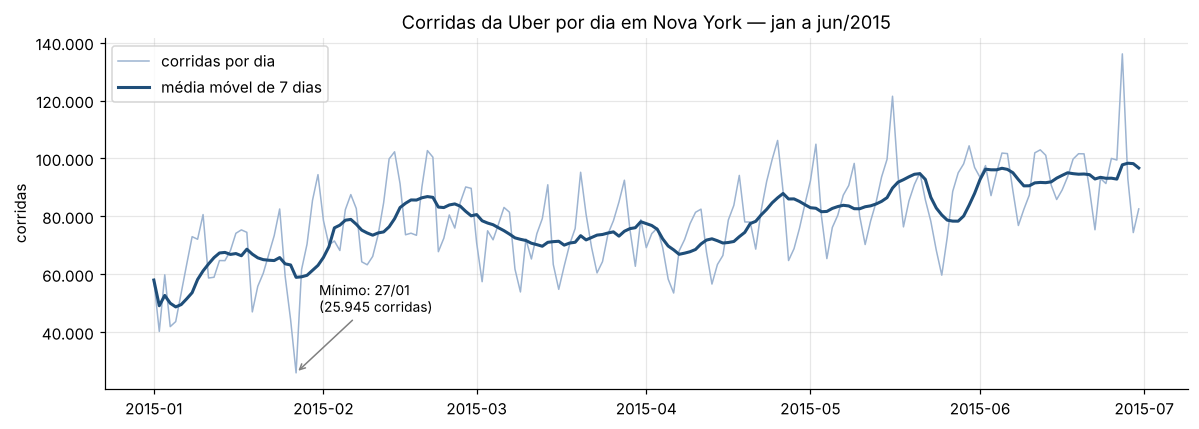

Média móvel de 7 dias: 51.507 (07/01) -> 96.714 (30/06), crescimento de 87,8%
Cinco dias de menor movimento:


+----------+--------+
|       dia|corridas|
+----------+--------+
|2015-01-27|   25945|
|2015-01-02|   40266|
|2015-01-04|   41925|
|2015-01-05|   43659|
|2015-01-26|   44289|
+----------+--------+
only showing top 5 rows


In [11]:
diario = (viagens_limpo.groupBy(F.to_date("data_hora").alias("dia"))
          .agg(F.count("*").alias("corridas"))
          .withColumn("media_movel_7d", F.avg("corridas").over(Window.orderBy("dia").rowsBetween(-6, 0)))
          .orderBy("dia"))
diario_pd = diario.toPandas()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diario_pd["dia"], diario_pd["corridas"], color="#9db4d1", lw=1, label="corridas por dia")
ax.plot(diario_pd["dia"], diario_pd["media_movel_7d"], color="#1f4e79", lw=2, label="média móvel de 7 dias")
nevasca = diario_pd.loc[diario_pd["corridas"].idxmin()]
ax.annotate(f"Mínimo: {nevasca['dia']:%d/%m}\n({br(nevasca['corridas'])} corridas)",
            xy=(nevasca["dia"], nevasca["corridas"]), xytext=(15, 40), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="gray"), fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: br(v)))
ax.set_title("Corridas da Uber por dia em Nova York — jan a jun/2015")
ax.set_ylabel("corridas")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

primeira, ultima = diario_pd["media_movel_7d"].iloc[6], diario_pd["media_movel_7d"].iloc[-1]
print(f"Média móvel de 7 dias: {br(primeira)} (07/01) -> {br(ultima)} (30/06), crescimento de {br(100 * (ultima / primeira - 1), 1)}%")
print("Cinco dias de menor movimento:")
diario.orderBy("corridas").select("dia", "corridas").show(5)

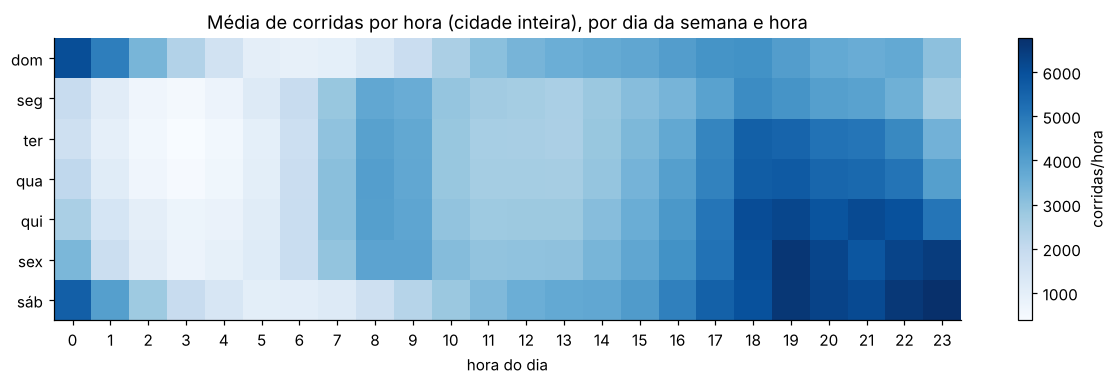

In [12]:
nomes_dias = {1: "dom", 2: "seg", 3: "ter", 4: "qua", 5: "qui", 6: "sex", 7: "sáb"}

perfil = (viagens_limpo
          .withColumn("dia_semana", F.dayofweek("data_hora"))
          .withColumn("hora_dia", F.hour("data_hora"))
          .groupBy("dia_semana", "hora_dia").count()
          # nº de ocorrências de cada dia da semana no semestre, para obter a média por hora
          .join(viagens_limpo.select(F.to_date("data_hora").alias("d")).distinct()
                .groupBy(F.dayofweek("d").alias("dia_semana")).agg(F.count("*").alias("n_dias")),
                "dia_semana")
          .withColumn("media_por_hora", F.col("count") / F.col("n_dias")))
mat = perfil.toPandas().pivot(index="dia_semana", columns="hora_dia", values="media_por_hora").sort_index()

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(mat.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7)); ax.set_yticklabels([nomes_dias[d] for d in mat.index])
ax.set_xticks(range(24)); ax.set_xlabel("hora do dia")
ax.grid(False)
ax.set_title("Média de corridas por hora (cidade inteira), por dia da semana e hora")
fig.colorbar(im, ax=ax, label="corridas/hora")
plt.tight_layout(); plt.show()

+-------------+--------+--------------------+
|      borough|   count|                 pct|
+-------------+--------+--------------------+
|    Manhattan|10371060|   72.70684015909744|
|     Brooklyn| 2322000|  16.278498326055796|
|       Queens| 1343945|   9.421794329375995|
|        Bronx|  220146|   1.543344656540861|
|Staten Island|    6959| 0.04878642112447127|
|          EWR|     105|7.361078054417997E-4|
+-------------+--------+--------------------+



+-------+------+---------+-------------------------+----+
|zona_id|count |borough  |nome_zona                |pct |
+-------+------+---------+-------------------------+----+
|161    |460732|Manhattan|Midtown Center           |3.23|
|231    |420356|Manhattan|TriBeCa/Civic Center     |2.95|
|234    |419045|Manhattan|Union Sq                 |2.94|
|79     |407591|Manhattan|East Village             |2.86|
|249    |323989|Manhattan|West Village             |2.27|
|230    |315919|Manhattan|Times Sq/Theatre District|2.21|
|68     |299781|Manhattan|East Chelsea             |2.1 |
|163    |296734|Manhattan|Midtown North            |2.08|
|170    |290550|Manhattan|Murray Hill              |2.04|
|132    |289169|Queens   |JFK Airport              |2.03|
+-------+------+---------+-------------------------+----+
only showing top 10 rows


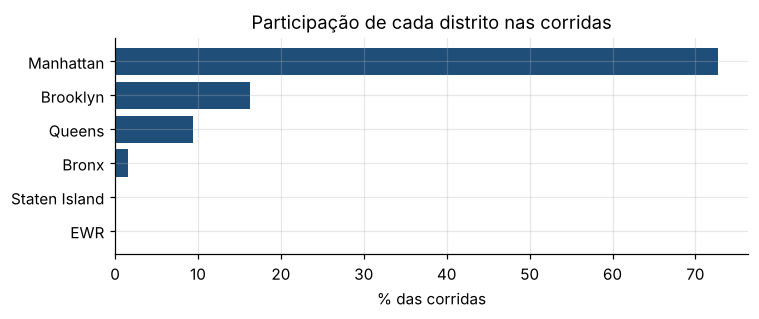

In [13]:
por_borough = (viagens_limpo.join(zonas, "zona_id")
               .groupBy("borough").count()
               .withColumn("pct", 100 * F.col("count") / n_limpo)
               .orderBy(F.desc("count")))
por_borough.show()

top_zonas = (viagens_limpo.groupBy("zona_id").count()
             .join(zonas, "zona_id")
             .withColumn("pct", F.round(100 * F.col("count") / n_limpo, 2))
             .orderBy(F.desc("count")))
top_zonas.show(10, truncate=False)

pb = por_borough.toPandas()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(pb["borough"][::-1], pb["pct"][::-1], color="#1f4e79")
ax.set_xlabel("% das corridas"); ax.set_title("Participação de cada distrito nas corridas")
plt.tight_layout(); plt.show()

**O que a exploração revela, e o que isso implica para a modelagem:**

* **Crescimento acelerado.** A média móvel de 7 dias passa de 51,5 mil corridas/dia (7 de janeiro) para 96,7 mil (30 de junho): +88% em seis meses, reflexo da expansão da Uber em 2015. A série **não é estacionária**: o mês de teste (junho) opera em um nível acima de qualquer mês de treino. Atributos que acompanham o nível recente de cada zona (defasagens e médias móveis) são indispensáveis, e referências baseadas em médias do passado tendem a subestimar a demanda.
* **Eventos extremos.** O dia de menor movimento é 27/01 (25.945 corridas, metade de um dia normal): a nevasca de janeiro de 2015, quando as autoridades proibiram a circulação de veículos não emergenciais na cidade. Os dias 2, 4 e 5 de janeiro (ressaca do Ano-Novo) também estão entre os mais fracos. Choques assim não são previsíveis pelo calendário; dependem de dados externos (clima), ausentes da base.
* **Ciclos diário e semanal distintos.** Nos dias úteis há um pico de manhã (8–9h) e outro, maior, no fim da tarde e início da noite (18–22h), crescente de segunda a sexta. Nos fins de semana o pico matinal desaparece e a demanda se desloca para a madrugada (0–2h de sábado e domingo) e para a noite de sexta e sábado. Como o formato do dia muda com o tipo de dia, criamos a interação `hora_fds` (seção 4.3).
* **Concentração espacial.** Manhattan responde por 72,7% das corridas; Brooklyn, 16,3%; Queens, 9,4%; Bronx, 1,5%; Staten Island e o aeroporto de Newark, menos de 0,1%. As dez zonas mais movimentadas (nove em Manhattan, mais o aeroporto JFK) somam 24,7% de tudo. Essa heterogeneidade exige que a zona entre como atributo e faz com que o erro absoluto do modelo seja dominado pelas zonas de Manhattan.

## 4. Engenharia de atributos e `Pipeline`

A engenharia de atributos tem duas partes, separadas por um motivo técnico:

1. **Construção da tabela analítica (seção 4.1 a 4.4)** — transformações que dependem do **histórico** de cada zona (agregação por hora, defasagens, médias móveis). Elas são feitas com funções de DataFrame/janela antes do `Pipeline`, como uma *feature store*: em produção, essas colunas seriam calculadas a partir do histórico já armazenado. Nenhuma delas "aprende" parâmetros com os dados, então não há risco de vazamento ao calculá-las sobre a base inteira — desde que cada linha olhe **somente para o passado**.
2. **`Pipeline` do Spark ML (seção 4.6)** — transformações que **aprendem parâmetros** a partir dos dados (dicionário de categorias do `StringIndexer`, médias e desvios do `StandardScaler`) e o próprio modelo. Essas etapas são ajustadas **somente no conjunto de treino**, o que elimina o vazamento de informação do teste.

### 4.1 Agregação para a grade zona × hora

In [14]:
with cronometro("agregação por zona e hora"):
    por_hora = (viagens_limpo
                .groupBy("zona_id", F.date_trunc("hour", "data_hora").alias("hora"))
                .agg(F.count("*").alias("corridas"))
                .cache())
    print("Combinações zona × hora com pelo menos uma corrida:", br(por_hora.count()))

Combinações zona × hora com pelo menos uma corrida: 777.891
[tempo] agregação por zona e hora: 3.4 s


### 4.2 Seleção das zonas e grade completa

Duas decisões:

* **Zonas com demanda relevante.** Zonas com menos de 10 corridas por dia, em média, são parques, cemitérios e áreas quase sem movimento; para elas a previsão hora a hora não tem valor operacional e a série é quase toda zero. O critério é calculado **apenas com o período de treino** (até 31/05), para que a seleção não use informação de junho;
* **Grade completa.** Uma hora sem nenhuma corrida simplesmente não aparece na agregação, mas é uma observação válida (demanda = 0). Montamos todas as combinações zona × hora com `crossJoin` e preenchemos as ausentes com zero. Sem isso, as defasagens (seção 4.4) pulariam horas e o modelo nunca veria demanda nula.

In [15]:
INICIO_TESTE = "2015-06-01"       # junho = teste
INICIO_VALIDACAO = "2015-05-01"   # maio = validação para ajuste de hiperparâmetros
DIAS_TREINO = 151                 # 01/01 a 31/05

zonas_relevantes = (por_hora.filter(F.col("hora") < INICIO_TESTE)
                    .groupBy("zona_id")
                    .agg((F.sum("corridas") / DIAS_TREINO).alias("media_diaria"))
                    .filter(F.col("media_diaria") >= 10)
                    .select("zona_id"))

total_zonas = por_hora.select("zona_id").distinct().count()
n_zonas = zonas_relevantes.count()
cobertura = (por_hora.join(zonas_relevantes, "zona_id").agg(F.sum("corridas")).first()[0]) / n_limpo
print(f"Zonas com alguma corrida: {total_zonas} | zonas selecionadas: {n_zonas}")
print(f"As zonas selecionadas concentram {br(100 * cobertura, 2)}% das corridas")

# Sequência de todas as horas do semestre gerada pelo próprio Spark
horas = spark.sql(
    "SELECT explode(sequence(timestamp'2015-01-01 00:00:00', "
    "timestamp'2015-06-30 23:00:00', interval 1 hour)) AS hora")
print("Horas no semestre:", horas.count())

grade = (zonas_relevantes.crossJoin(horas)
         .join(por_hora, ["zona_id", "hora"], "left")
         .fillna({"corridas": 0})
         .join(zonas, "zona_id", "left")
         .cache())
n_grade = grade.count()
n_zeros = grade.filter(F.col("corridas") == 0).count()
print(f"Linhas da grade: {br(n_grade)} (= {n_zonas} zonas × 4.344 horas) | horas com zero corridas: {br(100 * n_zeros / n_grade, 1)}%")
liberar(viagens_limpo)

Zonas com alguma corrida: 260 | zonas selecionadas: 216
As zonas selecionadas concentram 99,85% das corridas


Horas no semestre: 4344


Linhas da grade: 938.304 (= 216 zonas × 4.344 horas) | horas com zero corridas: 18,9%


### 4.3 Atributos de calendário

| Atributo | Construção | Intuição |
|---|---|---|
| `hora_dia` | hora 0–23 | ciclo diário (picos de manhã, fim de tarde e madrugada de fim de semana) |
| `dia_semana` | 1 = domingo … 7 = sábado | padrão semanal |
| `fim_semana` | 1 se sábado/domingo | comportamento de lazer vs. deslocamento casa–trabalho |
| `feriado` | 1 nos feriados federais do período (01/01, 19/01, 16/02, 25/05) | feriados se parecem com domingos |
| `hora_fds` | combinação `hora_dia` + `fim_semana` (48 categorias) | **interação**: o pico das 8h existe em dias úteis, mas não aos sábados. Modelos lineares não captam interações sozinhos, então a criamos explicitamente |

### 4.4 Defasagens e médias móveis (funções de janela)

A demanda de uma zona na próxima hora é fortemente explicada pelo seu passado recente e pelo mesmo horário em dias/semanas anteriores. Com uma janela **particionada por zona e ordenada pela hora**, criamos:

| Atributo | Definição |
|---|---|
| `lag_1h`, `lag_2h`, `lag_3h` | corridas 1, 2 e 3 horas antes — tendência imediata |
| `lag_24h`, `lag_25h` | mesma hora do dia anterior e a hora anterior a ela |
| `lag_168h`, `lag_169h` | mesma hora da semana anterior e a hora anterior a ela — padrão semanal |
| `media_24h` | média das últimas 24 horas |
| `media_168h` | média das últimas 168 horas — **nível** atual da zona |

Os pares (`lag_24h`, `lag_25h`) e (`lag_168h`, `lag_169h`) permitem ao modelo aprender *como a demanda variou da hora anterior para a hora-alvo* no dia/semana anteriores e aplicar essa variação ao valor recente (`lag_1h`).

Todas as janelas usam `rowsBetween(..., -1)` ou `lag(k ≥ 1)`: **nenhuma linha enxerga o valor da própria hora que se quer prever**. Como a grade é completa e contínua, "1 linha antes" equivale exatamente a "1 hora antes". As primeiras 169 horas de cada zona não têm histórico suficiente e são descartadas (período de aquecimento).

In [16]:
FERIADOS = ["2015-01-01", "2015-01-19", "2015-02-16", "2015-05-25"]
janela = Window.partitionBy("zona_id").orderBy("hora")

tabela = (grade
    # --- calendário ---
    .withColumn("hora_dia", F.hour("hora"))
    .withColumn("dia_semana", F.dayofweek("hora"))
    .withColumn("fim_semana", F.col("dia_semana").isin(1, 7).cast("int"))
    .withColumn("feriado", F.date_format("hora", "yyyy-MM-dd").isin(FERIADOS).cast("int"))
    .withColumn("hora_fds", F.concat_ws("_", F.col("hora_dia").cast("string"), F.col("fim_semana").cast("string")))
    # --- histórico (somente passado) ---
    .withColumn("lag_1h", F.lag("corridas", 1).over(janela))
    .withColumn("lag_2h", F.lag("corridas", 2).over(janela))
    .withColumn("lag_3h", F.lag("corridas", 3).over(janela))
    .withColumn("lag_24h", F.lag("corridas", 24).over(janela))
    .withColumn("lag_25h", F.lag("corridas", 25).over(janela))
    .withColumn("lag_168h", F.lag("corridas", 168).over(janela))
    .withColumn("lag_169h", F.lag("corridas", 169).over(janela))
    .withColumn("media_24h", F.avg("corridas").over(janela.rowsBetween(-24, -1)))
    .withColumn("media_168h", F.avg("corridas").over(janela.rowsBetween(-168, -1)))
    .withColumn("zona", F.col("zona_id").cast("string"))
    .dropna(subset=["lag_169h"]))      # remove o período de aquecimento

# Plano físico: repare no "Exchange hashpartitioning(zona_id, ...)" seguido de "Window".
# O Spark redistribui os dados por zona e calcula as janelas de cada zona de forma independente,
# o que em um cluster significa zonas diferentes processadas em máquinas diferentes.
tabela.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [zona_id#14, hora#4227, corridas#4245L, borough#8, nome_zona#9, hora_dia#4682, dia_semana#4683, fim_semana#4684, feriado#4685, hora_fds#4686, lag_1h#4687L, lag_2h#4688L, lag_3h#4689L, lag_24h#4690L, lag_25h#4691L, lag_168h#4692L, lag_169h#4693L, media_24h#4694, media_168h#4696, cast(zona_id#14 as string) AS zona#4698]
   +- Filter atleastnnonnulls(1, lag_169h#4693L)
      +- Window [lag(corridas#4245L, -1, null) windowspecdefinition(zona_id#14, hora#4227 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) AS lag_1h#4687L, lag(corridas#4245L, -2, null) windowspecdefinition(zona_id#14, hora#4227 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -2, -2)) AS lag_2h#4688L, lag(corridas#4245L, -3, null) windowspecdefinition(zona_id#14, hora#4227 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -3, -3)) AS lag_3h#4689L, lag(corridas#4245L, -24, null) windowspecdefinition(zona_id#14, hora#4227 ASC NULLS FIRST, specifiedwindow

In [17]:
with cronometro("materialização da tabela analítica"):
    tabela = tabela.cache()
    n_tabela = tabela.count()
print(f"Tabela analítica: {br(n_tabela)} linhas x {len(tabela.columns)} colunas")
tabela.select("zona", "nome_zona", "hora", "corridas", "lag_1h", "lag_24h", "lag_168h",
              "media_24h", "media_168h", "hora_fds", "feriado").show(5, truncate=False)

tabela.select("corridas", "lag_1h", "lag_168h", "media_168h").summary("mean", "stddev", "min", "50%", "max").show()
liberar(grade, por_hora)

[tempo] materialização da tabela analítica: 7.6 s
Tabela analítica: 901.800 linhas x 20 colunas
+----+------------+-------------------+--------+------+-------+--------+---------+-------------------+--------+-------+
|zona|nome_zona   |hora               |corridas|lag_1h|lag_24h|lag_168h|media_24h|media_168h         |hora_fds|feriado|
+----+------------+-------------------+--------+------+-------+--------+---------+-------------------+--------+-------+
|12  |Battery Park|2015-01-08 01:00:00|0       |0     |0      |1       |0.75     |0.4523809523809524 |1_0     |0      |
|12  |Battery Park|2015-01-08 02:00:00|0       |0     |0      |0       |0.75     |0.44642857142857145|2_0     |0      |
|12  |Battery Park|2015-01-08 03:00:00|0       |0     |0      |0       |0.75     |0.44642857142857145|3_0     |0      |
|12  |Battery Park|2015-01-08 04:00:00|0       |0     |0      |0       |0.75     |0.44642857142857145|4_0     |0      |
|12  |Battery Park|2015-01-08 05:00:00|0       |0     |0      |0

+-------+------------------+------------------+------------------+-------------------+
|summary|          corridas|            lag_1h|          lag_168h|         media_168h|
+-------+------------------+------------------+------------------+-------------------+
|   mean| 15.39236083388778|15.388954313595033|15.037239964515413|  15.22716611090002|
| stddev|30.837497885035276|30.833429869376825|30.315905762275957| 22.681942925524023|
|    min|                 0|                 0|                 0|0.05952380952380952|
|    50%|                 3|                 3|                 3|  3.517857142857143|
|    max|               609|               609|               609|  130.2797619047619|
+-------+------------------+------------------+------------------+-------------------+



### 4.5 Divisão temporal: treino, validação e teste

Em séries temporais, a divisão aleatória (`randomSplit`) **vaza informação do futuro**: o modelo treinaria com 14h de um dia e seria testado com 13h do mesmo dia, cujas defasagens ele já viu. Além disso, ele seria avaliado em um cenário irreal — em produção, sempre prevemos o futuro a partir do passado.

Por isso a divisão é cronológica:

| Conjunto | Período | Uso |
|---|---|---|
| **Treino de ajuste** | 08/01 a 30/04 | treinar as combinações de hiperparâmetros |
| **Validação** | 01/05 a 31/05 | escolher a melhor combinação |
| **Treino final** | 08/01 a 31/05 (ajuste + validação) | reajustar o modelo escolhido com todo o histórico disponível |
| **Teste** | 01/06 a 30/06 | avaliação final, usado **uma única vez** |

Também por esse motivo **não usamos `CrossValidator` nem `TrainValidationSplit`**: ambos sorteiam as linhas de cada dobra aleatoriamente, misturando passado e futuro. Usamos o `ParamGridBuilder` para gerar as combinações e fazemos a validação temporal explicitamente.

In [18]:
treino = tabela.filter(F.col("hora") < INICIO_TESTE).cache()
teste = tabela.filter(F.col("hora") >= INICIO_TESTE).cache()
treino_ajuste = treino.filter(F.col("hora") < INICIO_VALIDACAO).cache()
validacao = treino.filter(F.col("hora") >= INICIO_VALIDACAO).cache()

for nome, df in [("treino de ajuste", treino_ajuste), ("validação", validacao),
                 ("treino final", treino), ("teste", teste)]:
    r = df.agg(F.count("*").alias("n"), F.min("hora").alias("ini"), F.max("hora").alias("fim"),
               F.avg("corridas").alias("media")).first()
    print(f"{nome:17s}: {br(r['n']):>9s} linhas | {r['ini']:%d/%m %Hh} a {r['fim']:%d/%m %Hh} | média de {br(r['media'], 1)} corridas por zona-hora")

treino de ajuste :   585.576 linhas | 08/01 01h a 30/04 23h | média de 14,3 corridas por zona-hora


validação        :   160.704 linhas | 01/05 00h a 31/05 23h | média de 16,7 corridas por zona-hora


treino final     :   746.280 linhas | 08/01 01h a 31/05 23h | média de 14,8 corridas por zona-hora


teste            :   155.520 linhas | 01/06 00h a 30/06 23h | média de 18,1 corridas por zona-hora


### 4.6 Os `Pipelines`

Treinamos dois tipos de modelo, e cada um recebe a representação de atributos adequada a ele.

**Pipeline A — Regressão Linear**

`StringIndexer` → `OneHotEncoder` → `VectorAssembler` (numéricos) → `StandardScaler` → `VectorAssembler` (final) → `LinearRegression` → `SQLTransformer`

* As categorias (`zona`, `borough`, `hora_dia`, `dia_semana`, `hora_fds`) são convertidas em índices e depois em vetores *one-hot*. Um modelo linear não pode receber "zona 161" como número, pois trataria a zona 161 como "maior" que a 160;
* Os atributos numéricos são padronizados (média 0, desvio 1) pelo `StandardScaler`, ajustado só no treino. Isso deixa os coeficientes comparáveis entre si e ajuda a regularização (que penaliza coeficientes) a tratar todos os atributos na mesma escala;
* O `SQLTransformer` final corta previsões negativas em zero, já que não existe demanda negativa.

**Pipeline B — Gradient-Boosted Trees (GBT) com alvo relativo ao nível da zona**

`SQLTransformer` (normalização) → `StringIndexer` → `VectorAssembler` → `GBTRegressor` → `SQLTransformer` (volta à escala original)

* **Alvo relativo.** Em vez do número de corridas, o GBT prevê o **fator multiplicativo** em relação ao nível recente da zona: `y_rel = corridas / (media_168h + 1)`. As defasagens também são divididas pelo mesmo nível. Um fator 1,3 significa "30% acima da média da última semana". Duas hipóteses motivam a escolha:
  1. **Extrapolação:** árvores preveem a média das folhas e, portanto, nunca preveem valores acima dos que viram no treino. Como a demanda cresceu fortemente ao longo do semestre (seção 3.6), junho poderia ter zonas com volumes nunca vistos entre janeiro e maio;
  2. **Compartilhamento entre zonas:** em escala relativa, o mesmo padrão ("às 18h a demanda costuma ser 1,8× a média semanal") vale para zonas pequenas e grandes, de modo que cada divisão das árvores serve a todas as zonas, em vez de ser gasta separando níveis de volume.

  A seção 5.4 testa essas hipóteses com um modelo de controle, sem a normalização;
* **Codificação:** árvores tratam categorias nativamente, então `zona` e `borough` passam só pelo `StringIndexer` (o `VectorAssembler` propaga os metadados de categoria e o GBT faz divisões por grupos de zonas). O *one-hot* com 216 colunas apenas tornaria o treino mais lento. `StandardScaler` também não é necessário: árvores são invariantes à escala dos atributos — a normalização pelo nível cumpre o papel de padronização aqui, com significado de negócio;
* **Peso das observações:** o erro no fator relativo de uma zona com 200 corridas/hora vale muito mais (em corridas) do que o de uma zona com 2. Usamos `weightCol = media_168h + 1` para que o treino dê mais importância às zonas onde o erro absoluto é maior;
* O último `SQLTransformer` multiplica a previsão pelo nível e corta negativos, devolvendo **número de corridas**.

O alvo relativo (`y_rel`) é criado fora do pipeline porque depende da resposta, que não existe no momento da previsão. Assim o modelo salvo recebe apenas atributos e devolve diretamente o número previsto de corridas.

In [19]:
# ---------------- Pipeline A: Regressão Linear ----------------
CATEG_LR = ["zona", "borough", "hora_dia", "dia_semana", "hora_fds"]
NUM_LR = ["lag_1h", "lag_2h", "lag_3h", "lag_24h", "lag_25h", "lag_168h", "lag_169h",
          "media_24h", "media_168h", "feriado"]

def etapas_atributos_lr():
    indexadores = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CATEG_LR]
    ohe = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEG_LR],
                        outputCols=[f"{c}_ohe" for c in CATEG_LR], handleInvalid="keep")
    vetor_num = VectorAssembler(inputCols=NUM_LR, outputCol="num_vetor")
    escalador = StandardScaler(inputCol="num_vetor", outputCol="num_padronizado", withMean=True, withStd=True)
    vetor_final = VectorAssembler(inputCols=[f"{c}_ohe" for c in CATEG_LR] + ["num_padronizado"],
                                  outputCol="features")
    return indexadores + [ohe, vetor_num, escalador, vetor_final]

corta_negativos_lr = SQLTransformer(statement="SELECT *, GREATEST(previsao_bruta, 0.0) AS previsao FROM __THIS__")

# ---------------- Pipeline B: GBT com alvo relativo ----------------
DEFASAGENS = ["lag_1h", "lag_2h", "lag_3h", "lag_24h", "lag_25h", "lag_168h", "lag_169h", "media_24h"]
normaliza = SQLTransformer(statement=
    "SELECT *, " +
    ", ".join(f"{c} / (media_168h + 1) AS {c}_rel" for c in DEFASAGENS) +
    ", LOG1P(media_168h) AS nivel_log, media_168h + 1 AS peso FROM __THIS__")
ATRIB_GBT = (["zona_idx", "borough_idx", "hora_dia", "dia_semana", "fim_semana", "feriado", "nivel_log"]
             + [f"{c}_rel" for c in DEFASAGENS])

def etapas_atributos_gbt():
    return [normaliza,
            StringIndexer(inputCol="zona", outputCol="zona_idx", handleInvalid="keep"),
            StringIndexer(inputCol="borough", outputCol="borough_idx", handleInvalid="keep"),
            VectorAssembler(inputCols=ATRIB_GBT, outputCol="features")]

volta_escala = SQLTransformer(statement=
    "SELECT *, GREATEST(prediction * (media_168h + 1), 0.0) AS previsao FROM __THIS__")

def com_alvo_relativo(df):
    return df.withColumn("y_rel", F.col("corridas") / (F.col("media_168h") + 1))

print("Statement do SQLTransformer de normalização:\n", normaliza.getStatement())
print("\nAtributos do GBT:", ATRIB_GBT)

Statement do SQLTransformer de normalização:
 SELECT *, lag_1h / (media_168h + 1) AS lag_1h_rel, lag_2h / (media_168h + 1) AS lag_2h_rel, lag_3h / (media_168h + 1) AS lag_3h_rel, lag_24h / (media_168h + 1) AS lag_24h_rel, lag_25h / (media_168h + 1) AS lag_25h_rel, lag_168h / (media_168h + 1) AS lag_168h_rel, lag_169h / (media_168h + 1) AS lag_169h_rel, media_24h / (media_168h + 1) AS media_24h_rel, LOG1P(media_168h) AS nivel_log, media_168h + 1 AS peso FROM __THIS__

Atributos do GBT: ['zona_idx', 'borough_idx', 'hora_dia', 'dia_semana', 'fim_semana', 'feriado', 'nivel_log', 'lag_1h_rel', 'lag_2h_rel', 'lag_3h_rel', 'lag_24h_rel', 'lag_25h_rel', 'lag_168h_rel', 'lag_169h_rel', 'media_24h_rel']


## 5. Modelagem

### 5.1 Referências (*baselines*)

Um modelo só tem valor se superar regras simples que qualquer operador poderia aplicar sem aprendizado de máquina. Usamos quatro referências, todas calculadas sem olhar para o teste:

| Referência | Previsão para a hora *h* da zona *z* |
|---|---|
| Média do treino | média geral de corridas por zona-hora no treino (mesmo valor para tudo) |
| Perfil histórico | média do treino para a mesma zona, dia da semana e hora |
| Persistência | o que aconteceu na hora anterior (`lag_1h`) |
| Ingênuo sazonal | o que aconteceu na mesma hora da semana anterior (`lag_168h`) |

In [20]:
METRICAS = ["rmse", "mae", "r2"]
avaliadores = {m: RegressionEvaluator(labelCol="corridas", predictionCol="previsao", metricName=m) for m in METRICAS}

def avaliar(df_previsto, nome):
    # RMSE, MAE e R² com o RegressionEvaluator do Spark ML + WAPE (erro absoluto total / demanda total)
    df_previsto = df_previsto.withColumn("corridas", F.col("corridas").cast("double"))
    r = {m: avaliadores[m].evaluate(df_previsto) for m in METRICAS}
    tot = df_previsto.agg(F.sum(F.abs(F.col("corridas") - F.col("previsao"))).alias("erro"),
                          F.sum("corridas").alias("demanda")).first()
    r["wape"] = tot["erro"] / tot["demanda"]
    return {"modelo": nome, **r}

resultados = []

media_treino = treino.agg(F.avg("corridas")).first()[0]
resultados.append(avaliar(teste.withColumn("previsao", F.lit(media_treino)), "Ref.: média do treino"))

perfil_hist = treino.groupBy("zona", "dia_semana", "hora_dia").agg(F.avg("corridas").alias("previsao"))
resultados.append(avaliar(teste.join(perfil_hist, ["zona", "dia_semana", "hora_dia"], "left").fillna({"previsao": 0.0}),
                          "Ref.: perfil histórico"))
resultados.append(avaliar(teste.withColumn("previsao", F.col("lag_1h").cast("double")), "Ref.: persistência (1h)"))
resultados.append(avaliar(teste.withColumn("previsao", F.col("lag_168h").cast("double")), "Ref.: ingênuo sazonal (168h)"))

def mostrar(res):
    print(f"{'modelo':38s} {'RMSE':>8s} {'MAE':>8s} {'R²':>8s} {'WAPE':>8s}")
    for r in res:
        print(f"{r['modelo']:38s} {r['rmse']:8.3f} {r['mae']:8.3f} {r['r2']:8.4f} {100 * r['wape']:7.2f}%")

mostrar(resultados)

modelo                                     RMSE      MAE       R²     WAPE
Ref.: média do treino                    33.926   19.254  -0.0092  106.57%
Ref.: perfil histórico                   11.079    4.775   0.8924   26.43%
Ref.: persistência (1h)                  11.503    5.435   0.8840   30.08%
Ref.: ingênuo sazonal (168h)             12.713    5.192   0.8583   28.74%


### 5.2 Regressão Linear com ajuste de hiperparâmetros

Hiperparâmetros testados:

* `regParam` (intensidade da regularização): 0, 0,01, 0,1 e 1;
* `elasticNetParam`: 0 (Ridge, L2 — encolhe todos os coeficientes) ou 1 (Lasso, L1 — zera coeficientes pouco úteis).

Para economizar processamento, a parte de atributos do pipeline é ajustada **uma vez** no treino de ajuste e reaproveitada por todas as combinações; só a regressão é refeita. Isso não causa vazamento: indexadores e escalador continuam vendo apenas o treino de ajuste.

In [21]:
with cronometro("ajuste de hiperparâmetros da Regressão Linear"):
    atributos_lr = Pipeline(stages=etapas_atributos_lr()).fit(treino_ajuste)
    tr_lr = atributos_lr.transform(treino_ajuste).select("features", "corridas").cache()
    va_lr = atributos_lr.transform(validacao).select("features", "corridas").cache()
    print("Dimensão do vetor de atributos (Regressão Linear):", tr_lr.first()["features"].size)

    lr = LinearRegression(featuresCol="features", labelCol="corridas", predictionCol="previsao_bruta", maxIter=100)
    grade_lr = (ParamGridBuilder()
                .addGrid(lr.regParam, [0.0, 0.01, 0.1, 1.0])
                .addGrid(lr.elasticNetParam, [0.0, 1.0])
                .build())

    busca_lr = []
    for params in grade_lr:
        m = lr.fit(tr_lr, params)
        pred = corta_negativos_lr.transform(m.transform(va_lr))
        rmse = avaliadores["rmse"].evaluate(pred.withColumn("corridas", F.col("corridas").cast("double")))
        rp, en = params[lr.regParam], params[lr.elasticNetParam]
        busca_lr.append((rp, en, rmse))
        print(f"regParam={rp:<5} elasticNetParam={en:<4} -> RMSE validação = {rmse:.4f}")

melhor_rp, melhor_en, _ = min(busca_lr, key=lambda t: t[2])
print(f"\nMelhor combinação: regParam={melhor_rp}, elasticNetParam={melhor_en}")
liberar(tr_lr, va_lr)

Dimensão do vetor de atributos (Regressão Linear): 314


regParam=0.0   elasticNetParam=0.0  -> RMSE validação = 8.0291


regParam=0.0   elasticNetParam=1.0  -> RMSE validação = 8.0291


regParam=0.01  elasticNetParam=0.0  -> RMSE validação = 8.0284


regParam=0.01  elasticNetParam=1.0  -> RMSE validação = 8.0314


regParam=0.1   elasticNetParam=0.0  -> RMSE validação = 8.0285


regParam=0.1   elasticNetParam=1.0  -> RMSE validação = 8.0867


regParam=1.0   elasticNetParam=0.0  -> RMSE validação = 8.2649


regParam=1.0   elasticNetParam=1.0  -> RMSE validação = 8.6999
[tempo] ajuste de hiperparâmetros da Regressão Linear: 41.1 s

Melhor combinação: regParam=0.01, elasticNetParam=0.0


In [22]:
with cronometro("treino final da Regressão Linear (08/01 a 31/05)"):
    pipeline_lr = Pipeline(stages=etapas_atributos_lr() + [
        LinearRegression(featuresCol="features", labelCol="corridas", predictionCol="previsao_bruta",
                         maxIter=100, regParam=melhor_rp, elasticNetParam=melhor_en),
        corta_negativos_lr])
    modelo_lr = pipeline_lr.fit(treino)

pred_lr = modelo_lr.transform(teste).cache()
resultados.append(avaliar(pred_lr, "Regressão Linear"))
mostrar(resultados[-1:])

[tempo] treino final da Regressão Linear (08/01 a 31/05): 13.8 s


modelo                                     RMSE      MAE       R²     WAPE
Regressão Linear                          8.483    4.201   0.9369   23.26%


### 5.3 Gradient-Boosted Trees (alvo relativo) com ajuste de hiperparâmetros

Hiperparâmetros testados:

* `maxDepth` (profundidade de cada árvore — quantas interações entre atributos cada árvore consegue representar): 4 e 6;
* `maxIter` (número de árvores somadas em sequência): 50 e 100.

Fixos: `stepSize = 0.1` (taxa de aprendizado), `maxBins = 256` (precisa ser maior que o nº de zonas para o tratamento categórico) e `seed = 42` (reprodutibilidade).

O erro de validação é medido **na escala original (corridas)**, depois de desfazer a normalização, para que a escolha seja feita pela métrica que importa ao negócio.

In [23]:
with cronometro("ajuste de hiperparâmetros do GBT"):
    atributos_gbt = Pipeline(stages=etapas_atributos_gbt()).fit(com_alvo_relativo(treino_ajuste))
    tr_gbt = atributos_gbt.transform(com_alvo_relativo(treino_ajuste)).select("features", "y_rel", "peso").cache()
    va_gbt = atributos_gbt.transform(validacao).select("features", "corridas", "media_168h").cache()
    tr_gbt.count(); va_gbt.count()

    gbt = GBTRegressor(featuresCol="features", labelCol="y_rel", weightCol="peso",
                       stepSize=0.1, maxBins=256, seed=42)
    grade_gbt = (ParamGridBuilder()
                 .addGrid(gbt.maxDepth, [4, 6])
                 .addGrid(gbt.maxIter, [50, 100])
                 .build())

    busca_gbt = []
    for params in grade_gbt:
        t0 = time.time()
        m = gbt.fit(tr_gbt, params)
        pred = volta_escala.transform(m.transform(va_gbt))
        rmse = avaliadores["rmse"].evaluate(pred.withColumn("corridas", F.col("corridas").cast("double")))
        md_, it = params[gbt.maxDepth], params[gbt.maxIter]
        busca_gbt.append((md_, it, rmse))
        print(f"maxDepth={md_} maxIter={it:<4} -> RMSE validação = {rmse:.4f}   ({time.time() - t0:.0f} s)")

melhor_depth, melhor_iter, _ = min(busca_gbt, key=lambda t: t[2])
print(f"\nMelhor combinação: maxDepth={melhor_depth}, maxIter={melhor_iter}")
liberar(tr_gbt, va_gbt)

maxDepth=4 maxIter=50   -> RMSE validação = 7.7799   (59 s)


maxDepth=4 maxIter=100  -> RMSE validação = 7.4161   (109 s)


maxDepth=6 maxIter=50   -> RMSE validação = 7.5907   (88 s)


maxDepth=6 maxIter=100  -> RMSE validação = 7.4005   (217 s)
[tempo] ajuste de hiperparâmetros do GBT: 477.3 s

Melhor combinação: maxDepth=6, maxIter=100


In [24]:
with cronometro("treino final do GBT (08/01 a 31/05)"):
    pipeline_gbt = Pipeline(stages=etapas_atributos_gbt() + [
        GBTRegressor(featuresCol="features", labelCol="y_rel", weightCol="peso", stepSize=0.1, maxBins=256,
                     seed=42, maxDepth=melhor_depth, maxIter=melhor_iter),
        volta_escala])
    modelo_gbt = pipeline_gbt.fit(com_alvo_relativo(treino))

pred_gbt = modelo_gbt.transform(teste).cache()
resultados.append(avaliar(pred_gbt, "GBT (alvo relativo)"))
mostrar(resultados[-1:])

[tempo] treino final do GBT (08/01 a 31/05): 263.3 s


modelo                                     RMSE      MAE       R²     WAPE
GBT (alvo relativo)                       7.732    3.642   0.9476   20.16%


### 5.4 Experimento de controle: GBT sem a normalização

Para verificar se a normalização da seção 4.6 de fato ajuda, e por quê, treinamos o mesmo GBT, com os mesmos hiperparâmetros e atributos, prevendo diretamente o número de corridas (sem dividir pelo nível da zona e sem pesos). Se a hipótese da extrapolação estiver certa, a vantagem do alvo relativo deve aparecer sobretudo nas zona-horas de junho que superaram o recorde da zona no treino.

In [25]:
ATRIB_GBT_BRUTO = ["zona_idx", "borough_idx", "hora_dia", "dia_semana", "fim_semana", "feriado"] + DEFASAGENS + ["media_168h"]
with cronometro("treino do GBT sem normalização"):
    pipeline_gbt_bruto = Pipeline(stages=[
        StringIndexer(inputCol="zona", outputCol="zona_idx", handleInvalid="keep"),
        StringIndexer(inputCol="borough", outputCol="borough_idx", handleInvalid="keep"),
        VectorAssembler(inputCols=ATRIB_GBT_BRUTO, outputCol="features"),
        GBTRegressor(featuresCol="features", labelCol="corridas", predictionCol="previsao_bruta", stepSize=0.1,
                     maxBins=256, seed=42, maxDepth=melhor_depth, maxIter=melhor_iter),
        corta_negativos_lr])
    modelo_gbt_bruto = pipeline_gbt_bruto.fit(treino)

pred_gbt_bruto = modelo_gbt_bruto.transform(teste).cache()
resultados.append(avaliar(pred_gbt_bruto, "GBT sem normalização (controle)"))
mostrar(resultados[-1:])

[tempo] treino do GBT sem normalização: 194.5 s


modelo                                     RMSE      MAE       R²     WAPE
GBT sem normalização (controle)           8.013    3.750   0.9437   20.76%


In [26]:
# Diagnóstico: compara os dois GBTs separando as zona-horas de junho em que a demanda
# superou o máximo já observado no treino para aquela zona (onde é preciso extrapolar)
max_treino = treino.groupBy("zona").agg(F.max("corridas").alias("max_treino"))
comparacao = (teste.select("zona", "hora", "corridas")
              .join(max_treino, "zona")
              .join(pred_gbt.select("zona", "hora", F.col("previsao").alias("p_rel")), ["zona", "hora"])
              .join(pred_gbt_bruto.select("zona", "hora", F.col("previsao").alias("p_bruto")), ["zona", "hora"])
              .withColumn("acima_do_recorde", F.col("corridas") > F.col("max_treino")))

(comparacao.groupBy("acima_do_recorde")
 .agg(F.count("*").alias("zona_horas"),
      F.round(F.avg("corridas"), 1).alias("demanda_media"),
      F.round(F.avg(F.col("corridas") - F.col("p_bruto")), 2).alias("vies_gbt_sem_norm"),
      F.round(F.avg(F.col("corridas") - F.col("p_rel")), 2).alias("vies_gbt_relativo"),
      F.round(F.avg(F.abs(F.col("corridas") - F.col("p_bruto"))), 2).alias("mae_gbt_sem_norm"),
      F.round(F.avg(F.abs(F.col("corridas") - F.col("p_rel"))), 2).alias("mae_gbt_relativo"))
 .orderBy("acima_do_recorde")
 .show())

+----------------+----------+-------------+-----------------+-----------------+----------------+----------------+
|acima_do_recorde|zona_horas|demanda_media|vies_gbt_sem_norm|vies_gbt_relativo|mae_gbt_sem_norm|mae_gbt_relativo|
+----------------+----------+-------------+-----------------+-----------------+----------------+----------------+
|           false|    155364|         18.0|             0.09|             0.04|            3.72|            3.61|
|            true|       156|         99.4|            26.56|            31.08|           31.34|           33.03|
+----------------+----------+-------------+-----------------+-----------------+----------------+----------------+



**Resultado do experimento de controle.** O GBT sem normalização obteve RMSE 8,01 e MAE 3,75, contra 7,73 e 3,64 do GBT com alvo relativo: a normalização (junto com os pesos) traz um **ganho modesto e consistente**, de 3,5% no RMSE e 2,9% no MAE.

A tabela acima, porém, **não confirma a hipótese da extrapolação** como explicação desse ganho:

* Somente 156 das 155.520 zona-horas de junho (0,1%) superaram o recorde da zona no treino. O crescimento da demanda elevou o nível médio, mas raramente produziu valores fora da faixa já observada.
* Nessas 156 horas, os **dois** modelos subestimam muito (viés de +26,6 e +31,1 corridas, para uma demanda média de 99,4), e o modelo relativo é até um pouco pior. São picos atípicos, provavelmente ligados a eventos, que nenhum dos dois consegue antecipar.
* Fora delas, ambos têm viés praticamente nulo (+0,09 e +0,04). As defasagens já carregam o nível atual da zona, então mesmo o GBT bruto acompanha o crescimento.

A melhora vem, portanto, da segunda hipótese: na escala relativa, os padrões aprendidos em uma zona servem às demais, e cada divisão das árvores é aproveitada por zonas de todos os tamanhos. Esse é um bom exemplo de por que uma justificativa teórica precisa ser testada: a técnica funcionou, mas por um motivo diferente do que a motivou.

## 6. Avaliação e interpretação

### 6.1 Comparação no conjunto de teste (junho/2015)

Métricas, todas na escala de **corridas por zona-hora**:

* **RMSE** (raiz do erro quadrático médio): penaliza mais os erros grandes; mesma unidade do alvo;
* **MAE** (erro absoluto médio): erro típico, em corridas;
* **R²**: fração da variância da demanda explicada pelo modelo (1 = perfeito; 0 = tão bom quanto prever a média);
* **WAPE** (erro absoluto ponderado): soma dos erros absolutos dividida pela demanda total — lê-se como "erramos X% das corridas", métrica mais intuitiva para a operação.

modelo                                     RMSE      MAE       R²     WAPE
Ref.: média do treino                    33.926   19.254  -0.0092  106.57%
Ref.: perfil histórico                   11.079    4.775   0.8924   26.43%
Ref.: persistência (1h)                  11.503    5.435   0.8840   30.08%
Ref.: ingênuo sazonal (168h)             12.713    5.192   0.8583   28.74%
Regressão Linear                          8.483    4.201   0.9369   23.26%
GBT (alvo relativo)                       7.732    3.642   0.9476   20.16%
GBT sem normalização (controle)           8.013    3.750   0.9437   20.76%

Melhor referência: Ref.: perfil histórico
Regressão Linear: RMSE 23,4% menor e MAE 12,0% menor que a melhor referência
GBT (alvo relativo): RMSE 30,2% menor e MAE 23,7% menor que a melhor referência


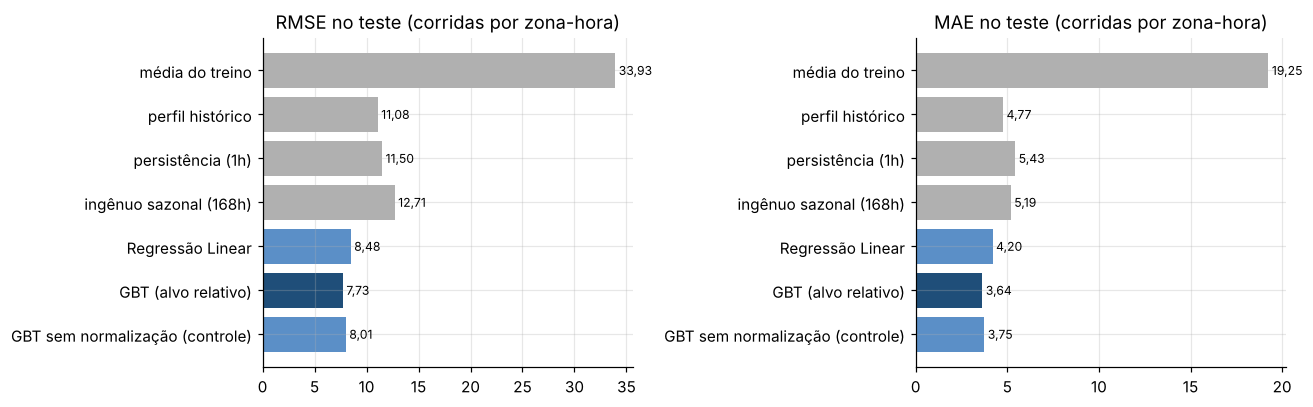

In [27]:
mostrar(resultados)

melhor_ref = min([r for r in resultados if r["modelo"].startswith("Ref.")], key=lambda r: r["rmse"])
res_gbt = next(r for r in resultados if r["modelo"] == "GBT (alvo relativo)")
res_lr = next(r for r in resultados if r["modelo"] == "Regressão Linear")
print(f"\nMelhor referência: {melhor_ref['modelo']}")
for r in (res_lr, res_gbt):
    print(f"{r['modelo']}: RMSE {br(100 * (1 - r['rmse'] / melhor_ref['rmse']), 1)}% menor e "
          f"MAE {br(100 * (1 - r['mae'] / melhor_ref['mae']), 1)}% menor que a melhor referência")

nomes = [r["modelo"].replace("Ref.: ", "") for r in resultados]
cores = ["#b0b0b0" if r["modelo"].startswith("Ref.") else ("#1f4e79" if r is res_gbt else "#5b8fc7") for r in resultados]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, ["rmse", "mae"]):
    vals = [r[m] for r in resultados]
    ax.barh(nomes[::-1], vals[::-1], color=cores[::-1])
    for i, v in enumerate(vals[::-1]):
        ax.text(v, i, f" {br(v, 2)}", va="center", fontsize=8)
    ax.set_title(m.upper() + " no teste (corridas por zona-hora)")
plt.tight_layout(); plt.show()

**Interpretação dos resultados no teste:**

* **O GBT com alvo relativo é o melhor modelo** em todas as métricas: RMSE 7,73, MAE 3,64 corridas, R² 0,948 e WAPE 20,2%. Em relação à melhor referência (o perfil histórico zona × dia × hora), reduz o RMSE em 30% e o MAE em 24%. A Regressão Linear também supera todas as referências (RMSE 8,48; MAE 4,20), mostrando que a maior parte do ganho vem da engenharia de atributos, e não apenas do algoritmo.
* **Cuidado com o R² alto.** Até as referências ingênuas têm R² entre 0,86 e 0,89, porque boa parte da variância da demanda é a diferença entre zonas (Midtown × Bronx) e o ciclo dia/noite, que qualquer regra razoável captura. O R² sozinho, portanto, superestima a qualidade. A comparação relevante é com as referências: o GBT elimina cerca de metade (51%) do erro quadrático que sobrava na melhor delas, já que (7,73 / 11,08)² ≈ 0,49.
* **Leitura de negócio.** Em junho, cada zona selecionada teve em média 18,1 corridas por hora. O erro típico do GBT é de 3,6 corridas por zona-hora, e o WAPE indica que 20% do volume seria alocado na zona-hora errada, contra 26% com a melhor regra simples. Para o reposicionamento de motoristas, é uma redução de cerca de um quarto no volume mal alocado.
* **Hiperparâmetros.** Na Regressão Linear, a regularização quase não fez diferença: com penalidade nula ou fraca, o RMSE de validação ficou entre 8,028 e 8,031. Com ~586 mil linhas e 314 atributos, a variância do modelo já é baixa, e regularizar forte (Lasso com `regParam` = 0,1 ou qualquer penalidade com `regParam` = 1) piorou o ajuste (*underfitting*). No GBT, árvores mais profundas e em maior número melhoraram a validação de forma consistente. A melhor combinação (profundidade 6, 100 árvores) ficou na borda da grade, o que sugere ganho adicional com grades maiores. Cada ajuste dessa combinação levou cerca de 3,5 minutos em 2 núcleos; em um cluster, as combinações da grade poderiam ser treinadas em paralelo.
* **Ausência de vazamento.** O teste (junho) só foi usado uma vez, depois de todas as escolhas; indexadores, escalador e modelos foram ajustados apenas com dados anteriores ao período avaliado; todas as defasagens olham apenas para o passado; e o critério de seleção das zonas usou somente o período de treino.

### 6.2 Previsto × real e resíduos

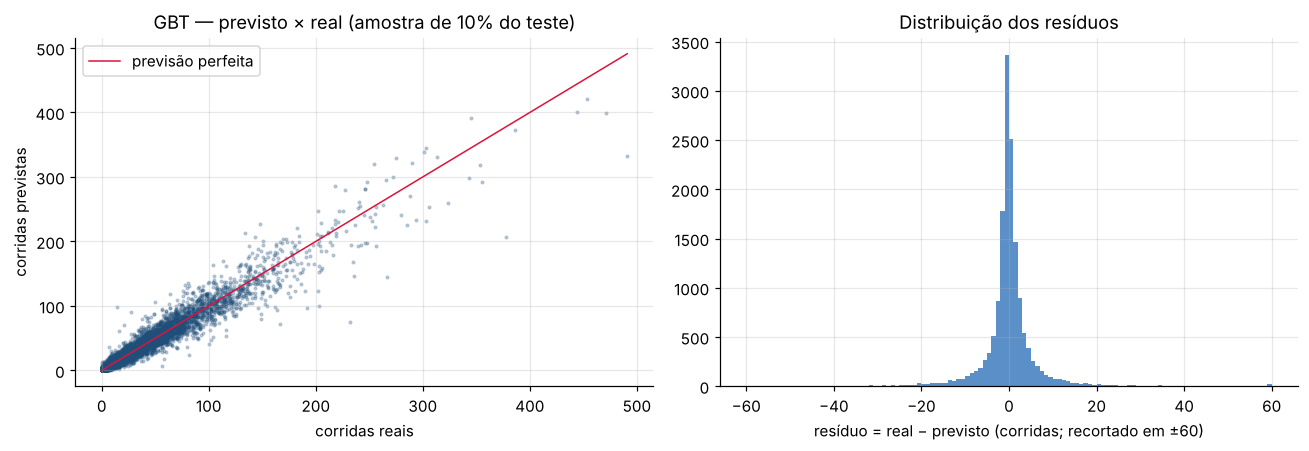

+-------+-------------------+
|summary|            residuo|
+-------+-------------------+
|   mean|0.07274158163165628|
| stddev|  7.731691210019478|
|     1%|-22.006173904450463|
|    25%|-1.4990082213667808|
|    50%|-0.1810249626283411|
|    75%| 1.5109306392568191|
|    99%|   24.8508998546683|
+-------+-------------------+



In [28]:
amostra = pred_gbt.select("corridas", "previsao").sample(fraction=0.1, seed=42).toPandas()
residuos = amostra["corridas"] - amostra["previsao"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.scatter(amostra["corridas"], amostra["previsao"], s=3, alpha=0.25, color="#1f4e79")
lim = max(amostra["corridas"].max(), amostra["previsao"].max())
ax.plot([0, lim], [0, lim], color="crimson", lw=1, label="previsão perfeita")
ax.set_xlabel("corridas reais"); ax.set_ylabel("corridas previstas")
ax.set_title("GBT — previsto × real (amostra de 10% do teste)"); ax.legend()
ax = axes[1]
ax.hist(residuos.clip(-60, 60), bins=120, color="#5b8fc7")
ax.set_xlabel("resíduo = real − previsto (corridas; recortado em ±60)")
ax.set_title("Distribuição dos resíduos")
plt.tight_layout(); plt.show()

pred_gbt.select((F.col("corridas") - F.col("previsao")).alias("residuo")) \
        .summary("mean", "stddev", "1%", "25%", "50%", "75%", "99%").show()

### 6.3 Onde o modelo erra mais

Erro do GBT por distrito:


+---------+-------------+----+--------+
|  borough|demanda_media| mae|wape_pct|
+---------+-------------+----+--------+
|Manhattan|         44.0|7.29|    16.6|
| Brooklyn|         11.4|2.75|    24.3|
|   Queens|          6.9|2.18|    31.4|
|    Bronx|          1.8|1.11|    61.1|
+---------+-------------+----+--------+



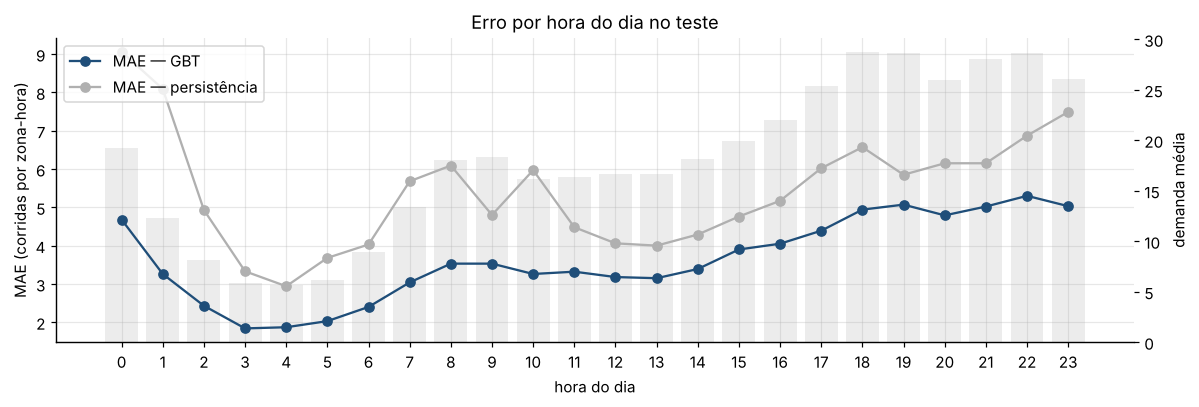

Dias de junho com maior erro relativo (GBT):


+----------+----------+-------+--------+
|       dia|dia_semana|demanda|wape_pct|
+----------+----------+-------+--------+
|2015-06-01|       seg|  93333|    27.0|
|2015-06-14|       dom|  90518|    23.1|
|2015-06-28|       dom|  92852|    22.5|
|2015-06-15|       seg|  85689|    22.3|
|2015-06-08|       seg|  76736|    22.1|
+----------+----------+-------+--------+
only showing top 5 rows


In [29]:
def erro_por(df, coluna):
    return (df.groupBy(coluna)
              .agg(F.round(F.avg("corridas"), 1).alias("demanda_media"),
                   F.round(F.avg(F.abs(F.col("corridas") - F.col("previsao"))), 2).alias("mae"),
                   F.round(100 * F.sum(F.abs(F.col("corridas") - F.col("previsao"))) / F.sum("corridas"), 1).alias("wape_pct")))

print("Erro do GBT por distrito:")
erro_por(pred_gbt, "borough").orderBy(F.desc("demanda_media")).show()

hora_gbt = erro_por(pred_gbt, "hora_dia").orderBy("hora_dia").toPandas()
hora_ref = (teste.withColumn("previsao", F.col("lag_1h").cast("double"))
            .transform(lambda d: erro_por(d, "hora_dia")).orderBy("hora_dia").toPandas())

fig, ax1 = plt.subplots(figsize=(11, 3.8))
ax1.plot(hora_gbt["hora_dia"], hora_gbt["mae"], marker="o", color="#1f4e79", label="MAE — GBT")
ax1.plot(hora_ref["hora_dia"], hora_ref["mae"], marker="o", color="#b0b0b0", label="MAE — persistência")
ax1.set_xlabel("hora do dia"); ax1.set_ylabel("MAE (corridas por zona-hora)"); ax1.set_xticks(range(24))
ax2 = ax1.twinx()
ax2.bar(hora_gbt["hora_dia"], hora_gbt["demanda_media"], alpha=0.15, color="gray", label="demanda média")
ax2.set_ylabel("demanda média"); ax2.grid(False)
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.legend(loc="upper left"); ax1.set_title("Erro por hora do dia no teste")
plt.tight_layout(); plt.show()

print("Dias de junho com maior erro relativo (GBT):")
rotulo_dia = F.element_at(F.array(*[F.lit(nomes_dias[i]) for i in range(1, 8)]), F.dayofweek("hora"))
(pred_gbt.groupBy(F.to_date("hora").alias("dia"), rotulo_dia.alias("dia_semana"))
 .agg(F.sum("corridas").alias("demanda"),
      F.round(100 * F.sum(F.abs(F.col("corridas") - F.col("previsao"))) / F.sum("corridas"), 1).alias("wape_pct"))
 .orderBy(F.desc("wape_pct")).show(5))

### 6.4 Uma semana de junho em três zonas com perfis diferentes

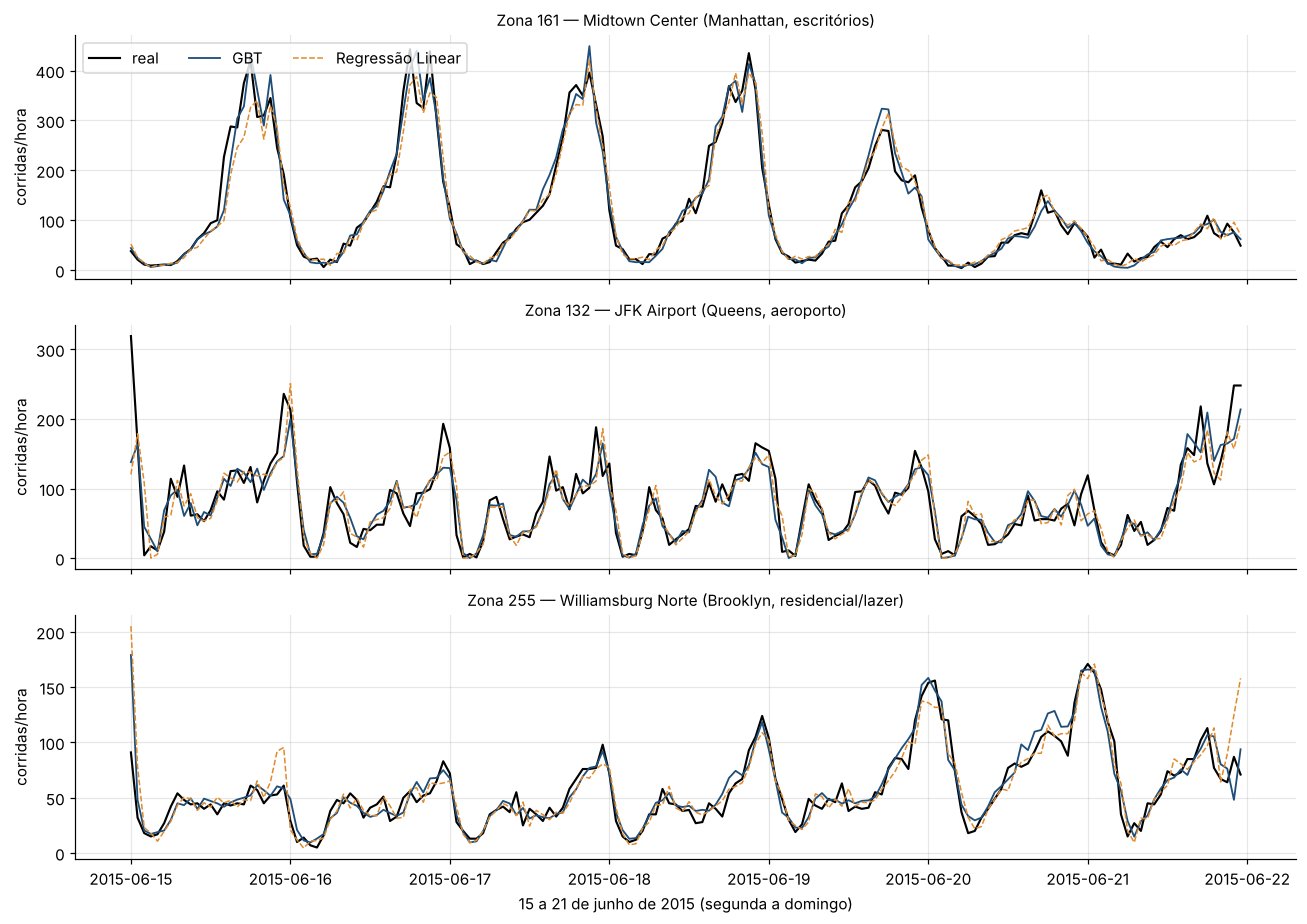

In [30]:
zonas_exemplo = {"161": "Midtown Center (Manhattan, escritórios)",
                 "132": "JFK Airport (Queens, aeroporto)",
                 "255": "Williamsburg Norte (Brooklyn, residencial/lazer)"}
semana = (pred_gbt.filter(F.col("zona").isin(list(zonas_exemplo)) &
                          F.col("hora").between("2015-06-15 00:00:00", "2015-06-21 23:00:00"))
          .join(pred_lr.select("zona", "hora", F.col("previsao").alias("previsao_lr")), ["zona", "hora"])
          .select("zona", "hora", "corridas", "previsao", "previsao_lr")
          .orderBy("zona", "hora").toPandas())

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for ax, (z, rotulo) in zip(axes, zonas_exemplo.items()):
    d = semana[semana["zona"] == z]
    ax.plot(d["hora"], d["corridas"], color="black", lw=1.4, label="real")
    ax.plot(d["hora"], d["previsao"], color="#1f4e79", lw=1.2, label="GBT")
    ax.plot(d["hora"], d["previsao_lr"], color="#e08a2e", lw=1, ls="--", label="Regressão Linear")
    ax.set_title(f"Zona {z} — {rotulo}", fontsize=10); ax.set_ylabel("corridas/hora")
axes[0].legend(ncol=3, loc="upper left")
axes[-1].set_xlabel("15 a 21 de junho de 2015 (segunda a domingo)")
plt.tight_layout(); plt.show()

### 6.5 O que o modelo aprendeu

In [31]:
gbt_treinado = modelo_gbt.stages[-2]          # GBTRegressionModel dentro do PipelineModel
importancias = sorted(zip(ATRIB_GBT, gbt_treinado.featureImportances.toArray()), key=lambda t: -t[1])
print(f"GBT final: {gbt_treinado.getNumTrees} árvores, profundidade máxima {gbt_treinado.getMaxDepth()}\n")
print("Importância dos atributos (GBT):")
for nome, imp in importancias:
    print(f"  {nome:15s} {imp:6.3f}  {'█' * int(round(imp * 60))}")

lr_treinado = modelo_lr.stages[-2]
print("\nRegressão Linear — coeficientes dos atributos numéricos padronizados")
print("(efeito, em corridas, de +1 desvio-padrão no atributo, mantidos os demais constantes):")
n_num = len(NUM_LR)
coefs_num = lr_treinado.coefficients.toArray()[-n_num:]
for nome, c in sorted(zip(NUM_LR, coefs_num), key=lambda t: -abs(t[1])):
    print(f"  {nome:12s} {c:+8.3f}")

GBT final: 100 árvores, profundidade máxima 6

Importância dos atributos (GBT):
  lag_1h_rel       0.375  ███████████████████████
  zona_idx         0.192  ████████████
  lag_168h_rel     0.180  ███████████
  hora_dia         0.080  █████
  lag_24h_rel      0.048  ███
  dia_semana       0.024  █
  media_24h_rel    0.020  █
  lag_169h_rel     0.019  █
  lag_2h_rel       0.018  █
  lag_3h_rel       0.012  █
  lag_25h_rel      0.012  █
  fim_semana       0.011  █
  feriado          0.004  
  nivel_log        0.004  
  borough_idx      0.000  

Regressão Linear — coeficientes dos atributos numéricos padronizados
(efeito, em corridas, de +1 desvio-padrão no atributo, mantidos os demais constantes):
  lag_1h        +20.654
  lag_168h      +12.642
  lag_24h        +7.317
  lag_169h       -5.825
  lag_25h        -4.522
  lag_3h         -2.113
  media_168h     -1.932
  media_24h      +0.962
  lag_2h         +0.679
  feriado        -0.108


**O que o modelo aprendeu e onde ele erra:**

* **Importância dos atributos (GBT).** O fator da hora anterior (`lag_1h_rel`, 0,375) é o principal sinal: a demanda tem forte inércia de curto prazo. Em seguida vêm a identidade da zona (`zona_idx`, 0,192), que permite a cada região ter seu próprio formato de dia, e a mesma hora da semana anterior (`lag_168h_rel`, 0,180), que traz o padrão semanal. A hora do dia (0,080) e o dia anterior (0,048) completam o quadro. O distrito (`borough_idx`) tem importância nula porque é redundante: a zona já identifica o distrito. `feriado` quase não pesa, já que há só três feriados no treino após o aquecimento.
* **Coeficientes da Regressão Linear.** A hora anterior domina (+20,7 corridas por desvio-padrão). O detalhe mais interessante são os **pares com sinais opostos**: `lag_168h` (+12,6) com `lag_169h` (−5,8), e `lag_24h` (+7,3) com `lag_25h` (−4,5). O modelo usa a **variação** entre a hora anterior e a hora-alvo, observada na semana e no dia anteriores, para corrigir o valor recente: se na segunda passada a demanda subiu das 17h para as 18h, ele espera subida semelhante hoje. A regressão redescobriu sozinha a ideia de diferença sazonal, clássica em previsão de séries temporais. Como as defasagens são correlacionadas entre si, os coeficientes devem ser lidos em conjunto, e não isoladamente.
* **Erro por distrito.** Manhattan tem o maior erro absoluto (MAE 7,3) mas o menor erro relativo (WAPE 16,6%). No Bronx o MAE é de só 1,1 corrida, mas o WAPE chega a 61%. Com média de 1,8 corrida por hora, a aleatoriedade natural de contagens pequenas (ruído de Poisson) já produz erro relativo alto, mesmo para um modelo que acerte a média. A previsão é mais útil onde a operação mais precisa dela: nas zonas de alto volume.
* **Erro por hora.** O erro acompanha o volume (mínimo às 3–5h, máximo às 18–23h), e o GBT supera a persistência em todas as horas. A vantagem é maior nas **transições**, como a subida da manhã (7–8h) e a meia-noite, justamente onde "repetir a última hora" falha.
* **Dias mais difíceis.** Os piores dias são segundas-feiras (1º, 8 e 15/06), na transição do fim de semana para os dias úteis, e dois domingos: 14/06, segundo domingo de junho, data tradicional da Parada Porto-Riquenha na Quinta Avenida, e 28/06, dia da Parada do Orgulho LGBT de Nova York ([NYC & Company, 2015](https://business.nyctourism.com/press-media/press-releases/celebrate-gay-pride-in-new-york-city-this-summer)). A ligação com esses eventos é uma hipótese plausível, não testada, já que a base não tem informação sobre eventos.
* **Uma semana em três zonas.** O modelo reproduz bem perfis muito diferentes: os picos de fim de tarde dos dias úteis em Midtown (até ~400 corridas/hora) e a queda no fim de semana; o padrão irregular do JFK, guiado por horários de voos, onde ficam os maiores desvios (como o pico da meia-noite de 15/06, não antecipado); e as noites de sexta e sábado em Williamsburg. No gráfico de dispersão, há leve subestimação nos volumes mais altos (acima de ~300 corridas/hora), comportamento comum em modelos que tendem a puxar os extremos para a média.

### 6.6 Limitações

1. **Sem variáveis externas.** Clima (chuva, neve — vide 27/01), eventos (shows, jogos, paradas) e falhas no transporte público alteram a demanda e não estão na base. Os maiores erros vêm justamente de picos atípicos.
2. **Demanda observada ≠ demanda real.** A base registra corridas **realizadas**. Pedidos não atendidos por falta de carro não aparecem, então o modelo aprende uma demanda limitada pela oferta da época.
3. **Horizonte de uma hora.** Para reposicionar motoristas a distâncias maiores seriam necessários horizontes de 2–3 horas, em que o erro cresce e as defasagens mais recentes deixam de estar disponíveis.
4. **Período curto, antigo e de forte crescimento.** Um semestre de 2015, uma única empresa, com testes em um único mês de verão. O mercado mudou muito desde então (concorrência, pandemia, regulação). Uma avaliação mais robusta usaria várias janelas de teste (validação com origem móvel).
5. **Duplicatas mantidas por evidência indireta.** Sem um ID de viagem, não é possível excluir que uma pequena fração seja duplicação verdadeira.
6. **Cobertura.** O modelo cobre as 216 zonas com demanda relevante (99,85% das corridas); as zonas de baixíssimo movimento ficaram de fora.
7. **Grade de hiperparâmetros pequena**, limitada pelo custo computacional em 2 núcleos, com a melhor combinação na borda da grade.
8. **Métricas simétricas.** Na operação, faltar carro (passageiro esperando) e sobrar carro (motorista ocioso) têm custos diferentes. Uma regressão quantílica ou uma função de perda assimétrica refletiria melhor esse trade-off.

## 7. Persistência

O modelo escolhido (GBT com alvo relativo) é salvo como um `PipelineModel` completo — normalização, indexadores, montagem do vetor, árvores e retorno à escala original. Quem carregar o modelo só precisa fornecer uma tabela com as colunas de calendário e defasagens (seção 4) e recebe a coluna `previsao` em número de corridas.

Usamos `model.write().overwrite().save(caminho)`, que é o `save()` do Spark ML com permissão para sobrescrever uma execução anterior (o `model.save(caminho)` simples falha se a pasta já existir). Também salvamos a Regressão Linear, para referência. Em seguida, recarregamos o modelo com `PipelineModel.load()` e conferimos que ele reproduz as mesmas previsões.

In [32]:
CAMINHO_GBT = "modelos/gbt_demanda_uber_zona_hora"
CAMINHO_LR = "modelos/regressao_linear_demanda_uber_zona_hora"

modelo_gbt.write().overwrite().save(CAMINHO_GBT)
modelo_lr.write().overwrite().save(CAMINHO_LR)

for caminho in (CAMINHO_GBT, CAMINHO_LR):
    tamanho = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(caminho) for f in fs)
    print(f"{caminho}: {br(tamanho / 1e6, 2)} MB | etapas: {sorted(os.listdir(os.path.join(caminho, 'stages')))}")

modelo_carregado = PipelineModel.load(CAMINHO_GBT)
verif = (modelo_carregado.transform(teste).select("zona", "hora", F.col("previsao").alias("previsao_recarregado"))
         .join(pred_gbt.select("zona", "hora", "previsao"), ["zona", "hora"]))
dif_max = verif.agg(F.max(F.abs(F.col("previsao") - F.col("previsao_recarregado")))).first()[0]
print(f"\nDiferença máxima entre o modelo em memória e o recarregado: {dif_max}")
print("Métricas do modelo recarregado:", {k: round(v, 4) for k, v in avaliar(modelo_carregado.transform(teste), "recarregado").items() if k != "modelo"})

modelos/gbt_demanda_uber_zona_hora: 0,90 MB | etapas: ['0_SQLTransformer_b0256057fe84', '1_StringIndexer_010a408c9d9c', '2_StringIndexer_ba29b861de94', '3_VectorAssembler_1d70db6e9b6e', '4_GBTRegressor_2fb325ff13d7', '5_SQLTransformer_ad5e5e37a578']
modelos/regressao_linear_demanda_uber_zona_hora: 0,02 MB | etapas: ['00_StringIndexer_4c97bb23517e', '01_StringIndexer_cf0ef79a6f06', '02_StringIndexer_ec8e3d4503ae', '03_StringIndexer_c5665493f293', '04_StringIndexer_ab1636a514b6', '05_OneHotEncoder_231d8732c02e', '06_VectorAssembler_bbae95a44004', '07_StandardScaler_5846b80e0525', '08_VectorAssembler_bafec62a52d4', '09_LinearRegression_0e1370d94ed5', '10_SQLTransformer_388d89c006ad']



Diferença máxima entre o modelo em memória e o recarregado: 0.0


Métricas do modelo recarregado: {'rmse': 7.732, 'mae': 3.6417, 'r2': 0.9476, 'wape': 0.2016}


## 8. Conclusão

**Resumo.** O trabalho percorreu todo o pipeline de dados massivos com Spark: 14,27 milhões de registros brutos foram lidos com schema explícito, auditados (nulos, zonas inválidas, duplicatas analisadas e mantidas com base em evidência), agregados em uma grade completa de 216 zonas × 4.344 horas e enriquecidos com atributos de calendário e de histórico por meio de funções de janela particionadas por zona. Sobre a tabela analítica de 901.800 linhas, dois `Pipelines` do Spark ML foram ajustados com validação temporal e avaliados uma única vez no mês de junho. O modelo final foi salvo com `save()` e recarregado com sucesso.

**Resposta à pergunta de negócio.** É possível prever quantas corridas cada zona terá na próxima hora com erro típico de **3,6 corridas** (WAPE de 20%, R² de 0,948). O GBT com alvo relativo reduziu o RMSE em 30% e o MAE em 24% em relação à melhor regra simples, e a Regressão Linear, mais simples e interpretável, também superou todas as referências. Os sinais mais importantes são a demanda da hora anterior, a identidade da zona e a mesma hora da semana anterior. A previsão é precisa nas zonas de alto volume, onde está a maior parte da operação (Manhattan, WAPE de 17%), e ruidosa nas de baixo volume.

**Possíveis melhorias.**

1. Incluir **dados de clima** (precipitação, temperatura, neve) e um **calendário de eventos**, que explicam boa parte dos maiores erros;
2. Avaliar com **origem móvel** (vários meses de teste) e com **dados recentes** da TLC (as viagens de aplicativos, hoje mais de 18 milhões por mês), verificando se o modelo generaliza;
3. Ampliar a **grade de hiperparâmetros** e testar modelos de contagem (`GeneralizedLinearRegression` com família Poisson ou Tweedie), mais adequados a zonas de baixo volume;
4. Prever **vários horizontes** (1 a 3 horas) e **intervalos de previsão** (regressão quantílica), mais úteis para decidir o reposicionamento;
5. Usar **granularidade mais fina** (15 minutos, malha de hexágonos) — cenário em que a tabela chega a centenas de milhões de linhas e um cluster Spark deixa de ser opção e passa a ser necessidade;
6. Levar o pipeline para **Spark Structured Streaming**, atualizando defasagens e previsões continuamente à medida que as corridas chegam.

### Referências

* FiveThirtyEight. *Uber TLC FOIL Response* (dados). https://github.com/fivethirtyeight/uber-tlc-foil-response
* NYC Taxi & Limousine Commission. *Taxi Zone Lookup Table* e dicionário de dados. https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
* NYC Taxi & Limousine Commission. Depoimento ao Comitê de Transporte e Infraestrutura do Conselho Municipal, 27/09/2024. https://www.nyc.gov/assets/tlc/downloads/pdf/testimony_9_27_24.pdf
* Apache Spark. *MLlib: Main Guide* — Pipelines, extração e transformação de atributos, regressão. https://spark.apache.org/docs/latest/ml-guide.html

In [33]:
spark.stop()